## Compare Zero-Shot Accuracy of Different models

This script is used to compare a list of different CLIP models in zero-shot classification.

### Comparison

At the end you will have a .csv file containing all the models names, the Top-1 and Top-2 Accuracies and the time to process an image to measure computation efficiency in ms/image.


In [1]:

# === Imports & Config ===
import os, time, json, math
from datetime import datetime
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
import open_clip
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, classification_report, top_k_accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import warnings
import gc

In [2]:
open_clip.list_pretrained()

[('RN50', 'openai'),
 ('RN50', 'yfcc15m'),
 ('RN50', 'cc12m'),
 ('RN101', 'openai'),
 ('RN101', 'yfcc15m'),
 ('RN50x4', 'openai'),
 ('RN50x16', 'openai'),
 ('RN50x64', 'openai'),
 ('ViT-B-32', 'openai'),
 ('ViT-B-32', 'laion400m_e31'),
 ('ViT-B-32', 'laion400m_e32'),
 ('ViT-B-32', 'laion2b_e16'),
 ('ViT-B-32', 'laion2b_s34b_b79k'),
 ('ViT-B-32', 'datacomp_xl_s13b_b90k'),
 ('ViT-B-32', 'datacomp_m_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_clip_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_laion_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_image_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_text_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_basic_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_s128m_b4k'),
 ('ViT-B-32', 'datacomp_s_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_clip_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_laion_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_image_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_text_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_basic_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_s13m_b4k'),
 ('ViT-

In [3]:
MODELS_LIST=selected_models = [
    # --- OpenAI Baselines ---
    ('RN50', 'openai'),
    ('RN101', 'openai'),
    ('RN50x64', 'openai'),
    ('ViT-B-32', 'openai'),
    ('ViT-B-16', 'openai'),
    ('ViT-L-14', 'openai'),
    ('ViT-L-14-336', 'openai'),

    # --- LAION / DataComp ---
    ('ViT-B-32', 'laion2b_s34b_b79k'),
    ('ViT-B-16', 'laion2b_s34b_b88k'),
    ('ViT-L-14', 'laion2b_s32b_b82k'),
    ('ViT-H-14', 'laion2b_s32b_b79k'),
    ('ViT-g-14', 'laion2b_s12b_b42k'),
    ('ViT-bigG-14', 'laion2b_s39b_b160k'),
    ('ViT-B-32', 'datacomp_xl_s13b_b90k'),
    ('ViT-B-16', 'datacomp_xl_s13b_b90k'),
    ('ViT-L-14', 'datacomp_xl_s13b_b90k'),
    ('ViT-H-14', 'dfn5b'),

    # --- MetaCLIP ---
    ('ViT-B-32', 'metaclip_400m'),
    ('ViT-B-32', 'metaclip_fullcc'),
    ('ViT-L-14', 'metaclip_400m'),
    ('ViT-L-14', 'metaclip_fullcc'),
    ('ViT-H-14', 'metaclip_fullcc'),
    ('ViT-bigG-14', 'metaclip_fullcc'),

    # --- SigLIP (Google) ---
    ('ViT-B-16-SigLIP', 'webli'),
    ('ViT-B-16-SigLIP-256', 'webli'),
    ('ViT-B-16-SigLIP-384', 'webli'),
    ('ViT-B-16-SigLIP-512', 'webli'),
    ('ViT-L-16-SigLIP-256', 'webli'),
    ('ViT-L-16-SigLIP-384', 'webli'),
    ('ViT-SO400M-14-SigLIP-384', 'webli'),
    ('ViT-SO400M-14-SigLIP-378', 'webli'),

    # --- SigLIP2 ---
    ('ViT-B-16-SigLIP2', 'webli'),
    ('ViT-B-16-SigLIP2-256', 'webli'),
    ('ViT-B-16-SigLIP2-384', 'webli'),
    ('ViT-B-16-SigLIP2-512', 'webli'),
    ('ViT-L-16-SigLIP2-256', 'webli'),
    ('ViT-L-16-SigLIP2-384', 'webli'),
    ('ViT-L-16-SigLIP2-512', 'webli'),
    ('ViT-SO400M-14-SigLIP2', 'webli'),
    ('ViT-SO400M-14-SigLIP2-378', 'webli'),
    ('ViT-SO400M-16-SigLIP2-384', 'webli'),
    ('ViT-SO400M-16-SigLIP2-512', 'webli'),
    ('ViT-gopt-16-SigLIP2-384', 'webli'),

    # --- EVA ---
    ('EVA01-g-14', 'laion400m_s11b_b41k'),
    ('EVA02-B-16', 'merged2b_s8b_b131k'),
    ('EVA02-L-14', 'merged2b_s4b_b131k'),
    ('EVA02-L-14-336', 'merged2b_s6b_b61k'),
    ('EVA02-E-14', 'laion2b_s4b_b115k'),
    ('EVA02-E-14-plus', 'laion2b_s9b_b144k'),

    # --- ConvNeXt ---
    ('convnext_base', 'laion400m_s13b_b51k'),
    ('convnext_base_w', 'laion2b_s13b_b82k'),
    ('convnext_large_d', 'laion2b_s26b_b102k_augreg'),
    ('convnext_large_d_320', 'laion2b_s29b_b131k_ft_soup'),
    ('convnext_xxlarge', 'laion2b_s34b_b82k_augreg'),

    # --- CoCa ---
    ('coca_ViT-B-32', 'laion2b_s13b_b90k'),
    ('coca_ViT-L-14', 'laion2b_s13b_b90k'),

    # --- CLIPA ---
    ('ViT-L-14-CLIPA', 'datacomp1b'),
    ('ViT-L-14-CLIPA-336', 'datacomp1b'),
    ('ViT-H-14-CLIPA', 'datacomp1b'),
    ('ViT-H-14-CLIPA-336', 'datacomp1b'),
    ('ViT-bigG-14-CLIPA', 'datacomp1b'),

    # --- ViTamin ---
    ('ViTamin-L', 'datacomp1b'),
    ('ViTamin-L-336', 'datacomp1b'),
    ('ViTamin-L2', 'datacomp1b'),
    ('ViTamin-L2-384', 'datacomp1b'),
    ('ViTamin-XL-336', 'datacomp1b'),
    ('ViTamin-XL-384', 'datacomp1b'),

    # --- PE-Core (SOTA) ---
    ('PE-Core-B-16', 'meta'),
    ('PE-Core-L-14-336', 'meta'),
    ('PE-Core-bigG-14-448', 'meta'),

    # --- Worldwide (MetaCLIP2) ---
    ('ViT-H-14-worldwide-378', 'metaclip2_worldwide'),
    ('ViT-bigG-14-worldwide', 'metaclip2_worldwide'),
    ('ViT-bigG-14-worldwide-378', 'metaclip2_worldwide'),
]


In [ ]:
DATASET_PATH="../datasets/ArchiStyles"

SPLIT="valid"
BATCH_SIZE = 64
TEMPLATES = [
    "a photo of {} architecture",
    "a photograph of {} architecture",
    "an image of {} architecture",
    "a picture of {} architecture",
    "a photo of the {} architectural style",
    "the {} architectural style",
    "a photo of a {} style building",
    "a {} style building",
    "a building in the {} style",
    "{}-style building",
    "a {} building",
    "a building of {} architecture",
    "a representation of {} architecture",
    "the facade of a {} building",
    "an example of {} architecture",
]

CSV_PATH = "benchmark_results.csv"
CSV_PER_CLASS_FOLDER = "./per_class_metrics/"
CONF_MATRIX_FOLDER="./confusoin_matrices/"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda:1


In [5]:
if not os.path.isdir(CSV_PER_CLASS_FOLDER):
    os.makedirs(CSV_PER_CLASS_FOLDER)
if not os.path.isdir(CONF_MATRIX_FOLDER):
    os.makedirs(CONF_MATRIX_FOLDER)

assert os.path.isdir(DATASET_PATH), f"DATASET_PATH not found: {DATASET_PATH}"
split_path = os.path.join(DATASET_PATH, SPLIT)
assert os.path.isdir(split_path), f"Split '{SPLIT}' not found in {DATASET_PATH}"




assert os.path.isdir(DATASET_PATH), f"DATASET_PATH not found: {DATASET_PATH}"
split_path = os.path.join(DATASET_PATH, SPLIT)
assert os.path.isdir(split_path), f"Split '{SPLIT}' not found in {DATASET_PATH}"
ds = ImageFolder(split_path)
classnames = ds.classes
num_classes = len(classnames)

print("Number of Classes: ", num_classes)
print("Classes example: ", classnames[:10])


def make_prompts(cname):
    return 

# Make the prompt from the templates prompts
all_prompts, class_offsets = [], [0]
for cname in classnames:
    ps = [t.format(cname) for t in TEMPLATES] + [f"{cname} architecture"]
    all_prompts.extend(ps)
    class_offsets.append(len(all_prompts))



Number of Classes:  25
Classes example:  ['Achaemenid', 'American Foursquare', 'American craftsman style', 'Ancient Egyptian', 'Art Deco', 'Art Nouveau', 'Baroque', 'Bauhaus', 'Beaux-Arts', 'Byzantine']


In [6]:
def evaluate(model,
            tokenizer:(open_clip.tokenizer.SimpleTokenizer | open_clip.tokenizer.HFTokenizer | open_clip.tokenizer.SigLipTokenizer),
            dl : DataLoader):

    # Tokenize and encode prompts

    tokens = tokenizer(all_prompts).to(device)

    with torch.no_grad():
        text_features = model.encode_text(tokens)
        text_features = text_features / torch.linalg.norm(text_features,dim=-1, keepdim=True)

    
    y_true, y_pred = [], []
    probs_collector = []
    model_dtype = next(model.parameters()).dtype

    with torch.no_grad():
        for imgs, labels in dl:
            imgs = imgs.to(device, dtype=model_dtype)
            img_features = model.encode_image(imgs)
            img_features = img_features / torch.linalg.norm(img_features,dim=-1, keepdim=True)

            # native logit scale  * custom temperature
            logit_scale = model.logit_scale.exp() #* temp
            logits = logit_scale * (img_features @ text_features.T)

            # class prompt aggregation
            class_logits = []
            for i in range(num_classes):
                s, e = class_offsets[i], class_offsets[i+1]
                class_logits.append(logits[:, s:e].mean(dim=1))
            class_logits = torch.stack(class_logits, dim=1)

            prob = class_logits.softmax(dim=-1)
            pred = prob.argmax(dim=-1)

            y_true.extend(labels.tolist())
            y_pred.extend(pred.tolist())
            probs_collector.append(prob.cpu().numpy())

    y_true = np.array(y_true, dtype=int)
    y_pred = np.array(y_pred, dtype=int)
    probs = np.concatenate(probs_collector, axis=0)

    top1 = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    top2 = top_k_accuracy_score(y_true, probs, k=min(2, num_classes), labels=np.arange(num_classes))
    top3 = top_k_accuracy_score(y_true, probs, k=min(3, num_classes), labels=np.arange(num_classes))

    return top1, macro_f1, top2, top3, y_true, y_pred, probs


In [7]:
# Latency (ms/img) measured on some batches (with warm up)
def measure_latency(model, dl : DataLoader, num_batches=150, warmup_batches=20):
    model_dtype = next(model.parameters()).dtype
    # warmup
    it = iter(dl)
    for _ in range(warmup_batches):
        try:
            imgs, _ = next(it)
        except StopIteration:
            it = iter(dl)
            imgs, _ = next(it)
        imgs = imgs.to(device, dtype=model_dtype,non_blocking=True)
        with torch.no_grad():
            _ = model.encode_image(imgs)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    # timed
    times = []
    it = iter(dl)
    for _ in range(num_batches):
        try:
            imgs, _ = next(it)
        except StopIteration:
            it = iter(dl)
            imgs, _ = next(it)
        imgs = imgs.to(device, dtype=model_dtype, non_blocking=True)
        if torch.cuda.is_available():
            torch.cuda.synchronize()  # Ensure transfer is complete
        if torch.cuda.is_available():
            start_event = torch.cuda.Event(enable_timing=True)
            end_event = torch.cuda.Event(enable_timing=True)
            
            start_event.record()
            with torch.no_grad():
                _ = model.encode_image(imgs)
            end_event.record()
            
            torch.cuda.synchronize()
            dt_ms = start_event.elapsed_time(end_event)  # Already in milliseconds
        else:
            t0 = time.perf_counter()  # More precise than time.time()
            with torch.no_grad():
                _ = model.encode_image(imgs)
            dt_ms = (time.perf_counter() - t0) * 1000.0
        
        ms_per_img = dt_ms / imgs.size(0)
        times.append(ms_per_img)
    
    # Return mean and std for better insight
    times = np.array(times)
    return {
        'mean_ms': float(np.mean(times)),
        'std_ms': float(np.std(times)),
#        'median_ms': float(np.median(times)),
#        'min_ms': float(np.min(times)),
#        'max_ms': float(np.max(times))
    }
    #return float(np.mean(times))



In [8]:
def save_to_csv(row:dict):
    df = pd.DataFrame([row])
    display(df)

    # Aggiungi le performance al csv con tutti i modelli
    if os.path.exists(CSV_PATH):
        old = pd.read_csv(CSV_PATH)
        out = pd.concat([old, df], ignore_index=True)
    else:
        out = df.copy()
    out.to_csv(CSV_PATH, index=False)

In [ ]:
# saves the per class performance in the file ./<CSV_PER_CLASS_FOLDER>/<model_name>.csv
# also saves the confusion matrix in a file ./<CONF_MATRIX_FOLDER>/<model_name
def save_performance_per_class(y_true,y_pred,model_name:str):
    df=pd.DataFrame(classification_report(y_true, y_pred, target_names=classnames, digits=4 , zero_division=0,output_dict=True))
    df=df.transpose()
    df.columns=["Precision","Recall","F1-score","Support"]
    df.to_csv(os.path.join(CSV_PER_CLASS_FOLDER, model_name+'.csv'), index=True)


    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        display_labels=classnames,
        normalize="true",           # percentuali per riga
        cmap="Blues",
        include_values=False,       # evita numeri sopra le celle se hai tante classi
        xticks_rotation=90,
        ax=ax,
        colorbar=True
    )
    
    ax.set_title("Confusion Matrix (normalized)")
    plt.tight_layout()
    plt.savefig(os.path.join(CONF_MATRIX_FOLDER, model_name))
    plt.close()

Model RN50, openai  (1/73)


,Timestamp,Model,Pretrained,Scenario,Techniques,Top-1 Acc,Top-2 Acc,Top-3 Acc,Macro-F1,Latency (ms/img),Classes,Batch size
0,2025-09-07T17:37:50.003875+02:00,RN50,openai,Zero-shot (valid),Prompt ensemble(15 prompts),0.5373,0.7164,0.8083,0.5223,3.88 ± 0.27 ms,25,64


Model RN101, openai  (2/73)


,Timestamp,Model,Pretrained,Scenario,Techniques,Top-1 Acc,Top-2 Acc,Top-3 Acc,Macro-F1,Latency (ms/img),Classes,Batch size
0,2025-09-07T17:37:58.292109+02:00,RN101,openai,Zero-shot (valid),Prompt ensemble(15 prompts),0.5326,0.7031,0.7936,0.5167,7.18 ± 0.28 ms,25,64


Model RN50x64, openai  (3/73)


...

,Timestamp,Model,Pretrained,Scenario,Techniques,Top-1 Acc,Top-2 Acc,Top-3 Acc,Macro-F1,Latency (ms/img),Classes,Batch size
0,2025-09-07T18:46:32.963077+02:00,ViT-H-14-worldwide-378,metaclip2_worldwide,Zero-shot (valid),Prompt ensemble(15 prompts),0.719,0.8455,0.8995,0.7036,65.90 ± 1.32 ms,25,64


Model ViT-bigG-14-worldwide, metaclip2_worldwide  (72/73)


,Timestamp,Model,Pretrained,Scenario,Techniques,Top-1 Acc,Top-2 Acc,Top-3 Acc,Macro-F1,Latency (ms/img),Classes,Batch size
0,2025-09-07T18:48:47.227226+02:00,ViT-bigG-14-worldwide,metaclip2_worldwide,Zero-shot (valid),Prompt ensemble(15 prompts),0.7523,0.8728,0.9154,0.7448,70.11 ± 1.36 ms,25,64


Model ViT-bigG-14-worldwide-378, metaclip2_worldwide  (73/73)


,Timestamp,Model,Pretrained,Scenario,Techniques,Top-1 Acc,Top-2 Acc,Top-3 Acc,Macro-F1,Latency (ms/img),Classes,Batch size
0,2025-09-07T18:54:23.154197+02:00,ViT-bigG-14-worldwide-378,metaclip2_worldwide,Zero-shot (valid),Prompt ensemble(15 prompts),0.7443,0.8762,0.9274,0.7404,176.71 ± 1.02 ms,25,64


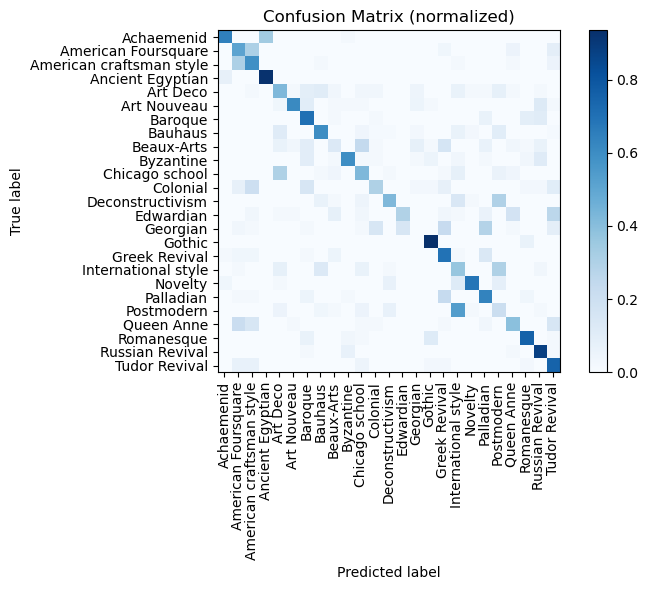

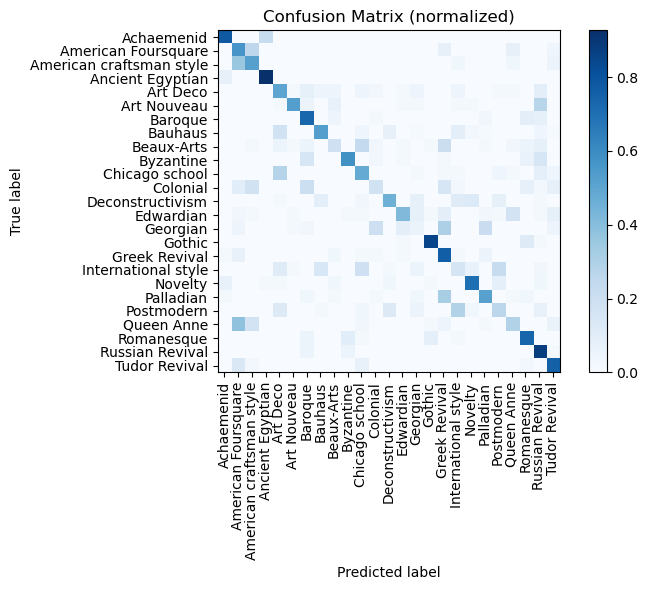

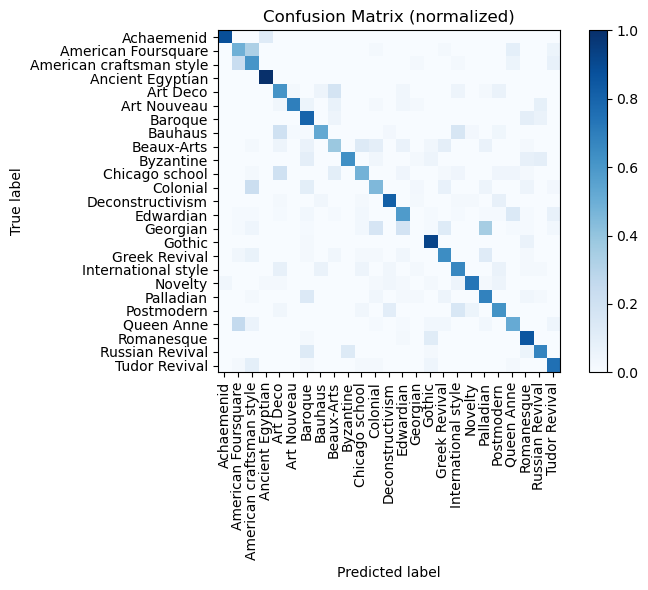

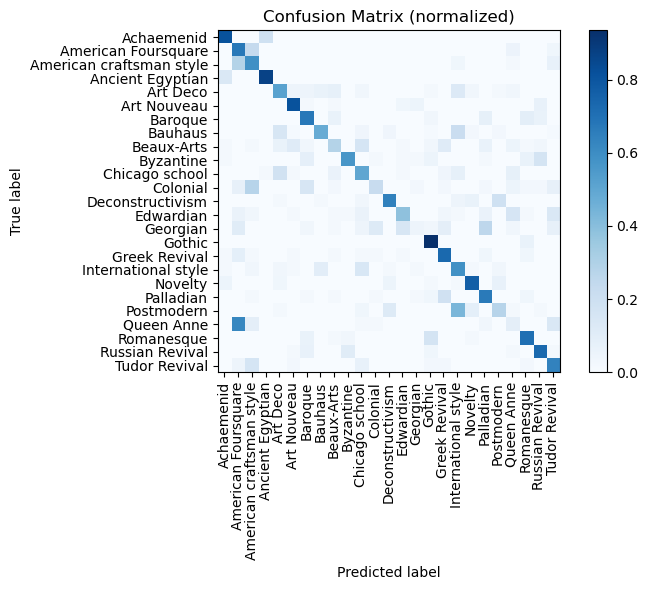

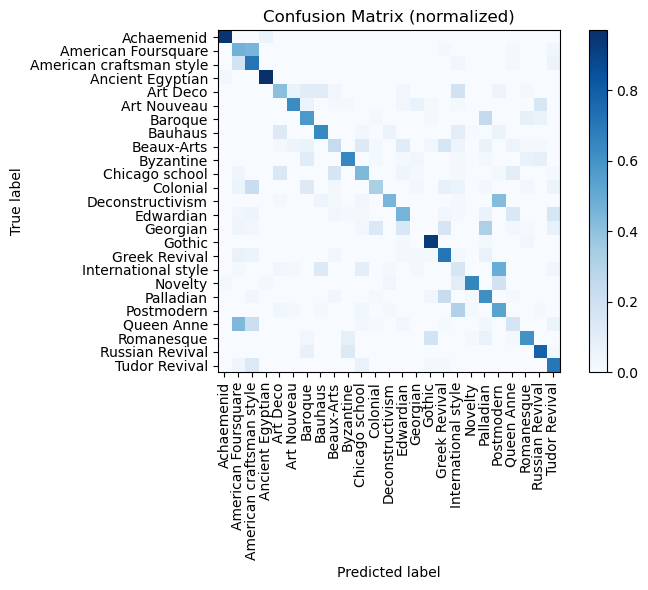

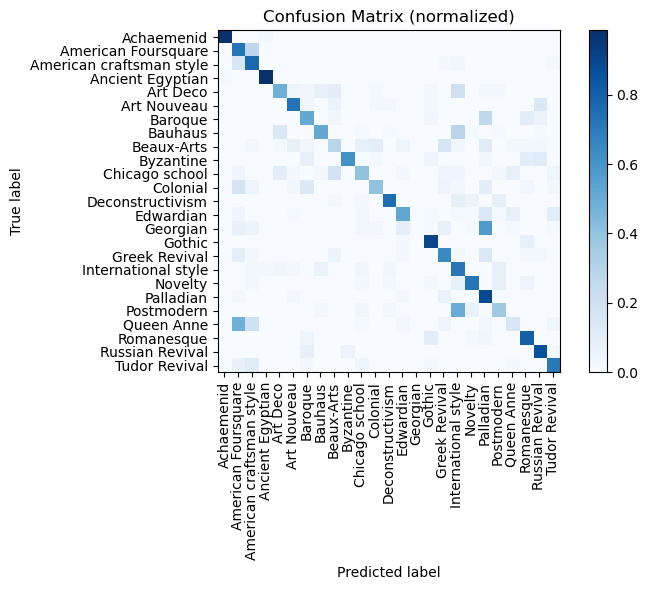

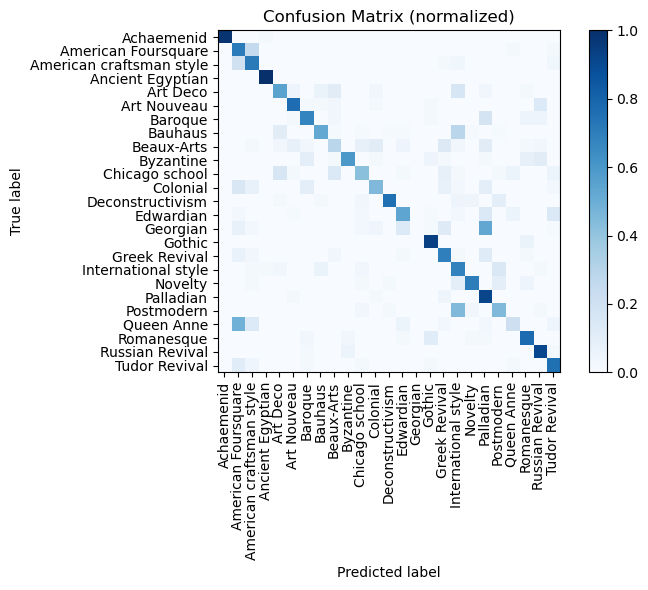

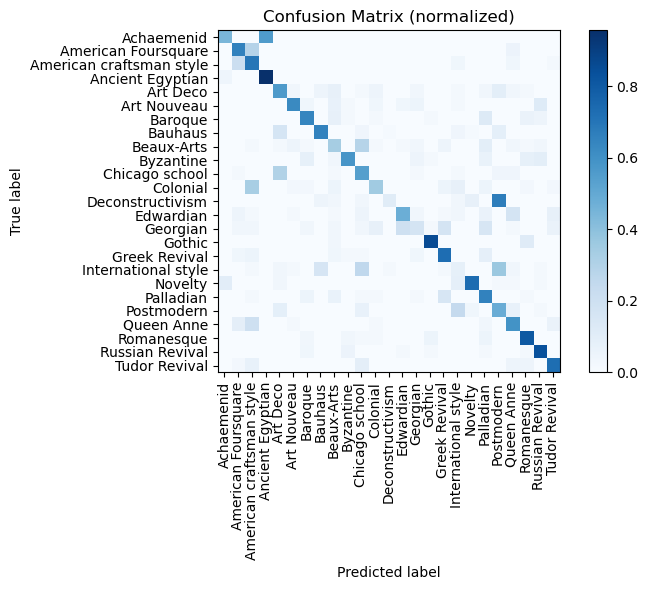

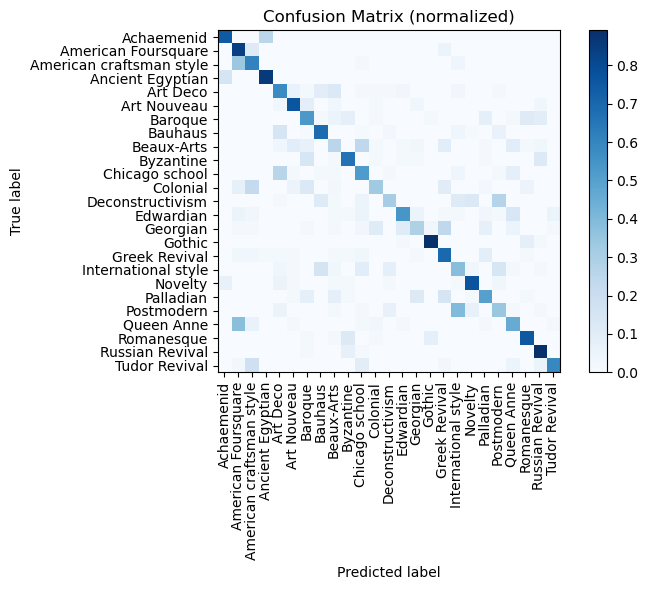

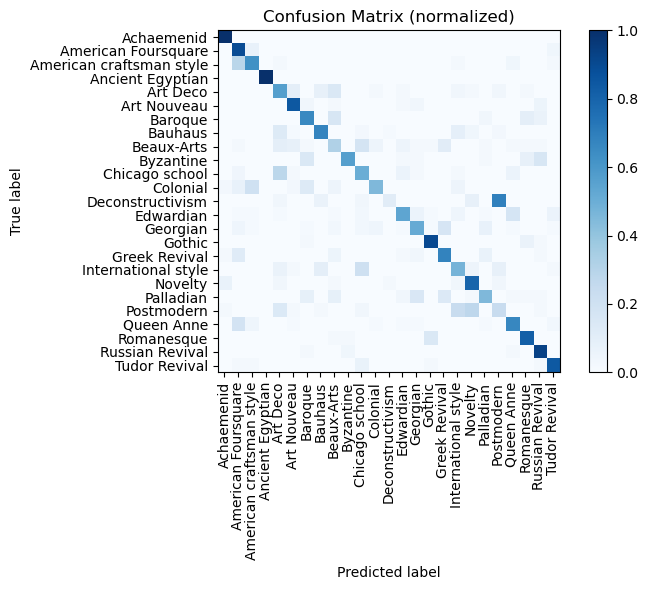

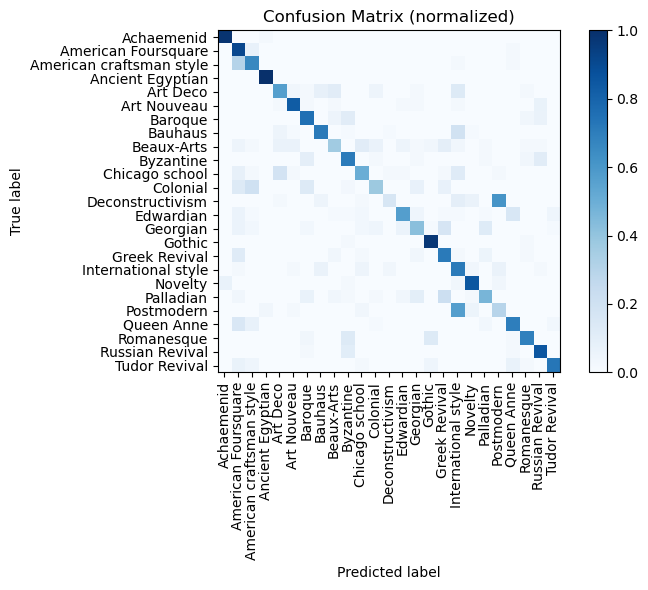

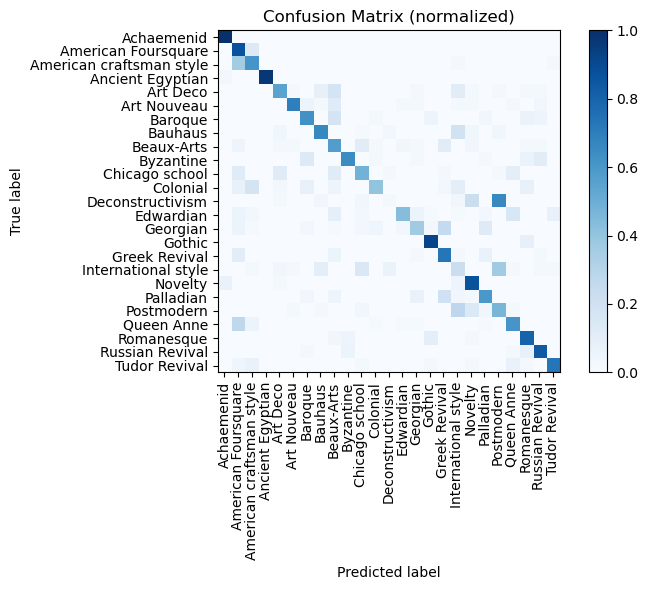

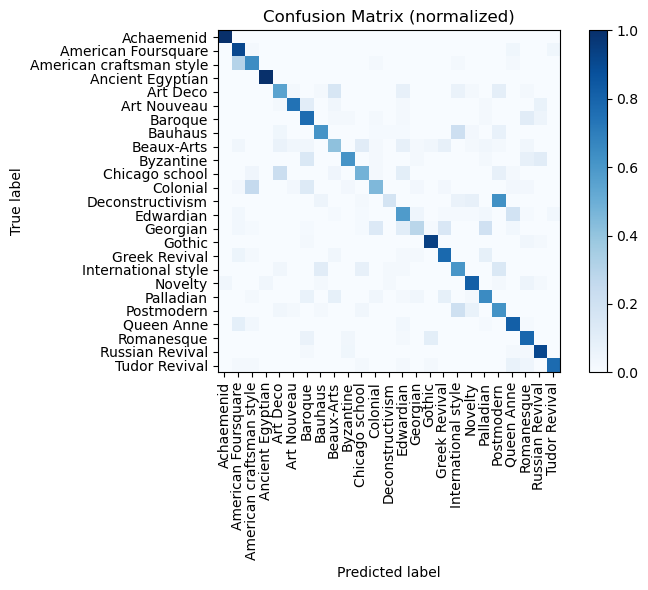

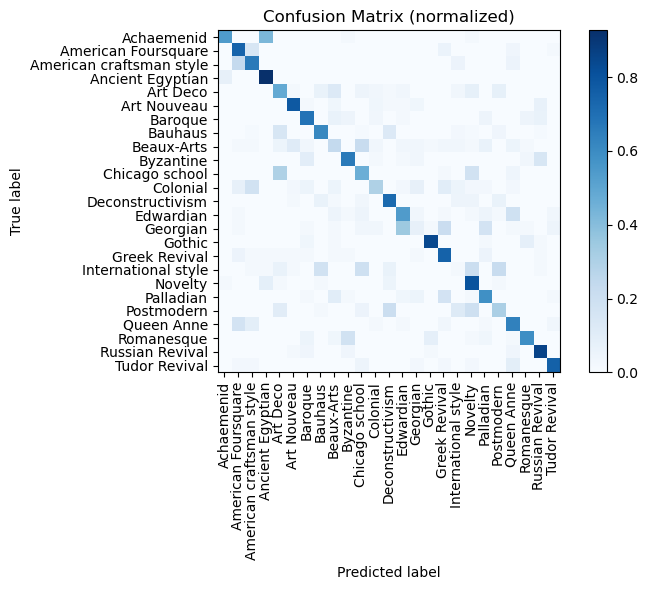

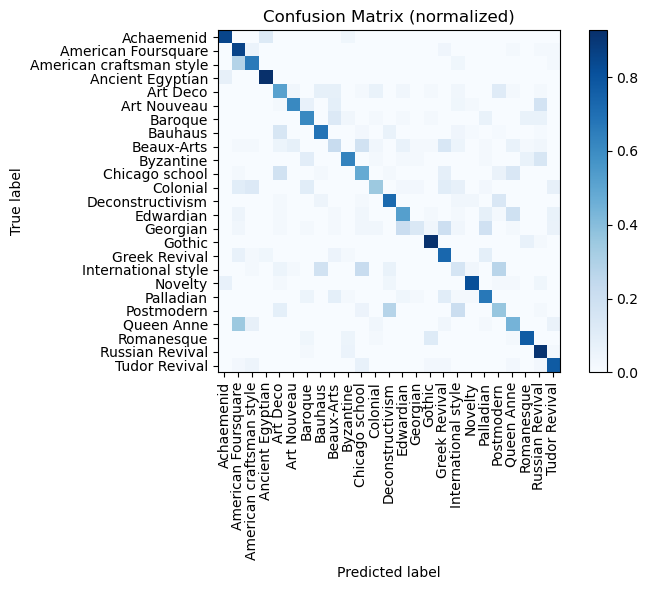

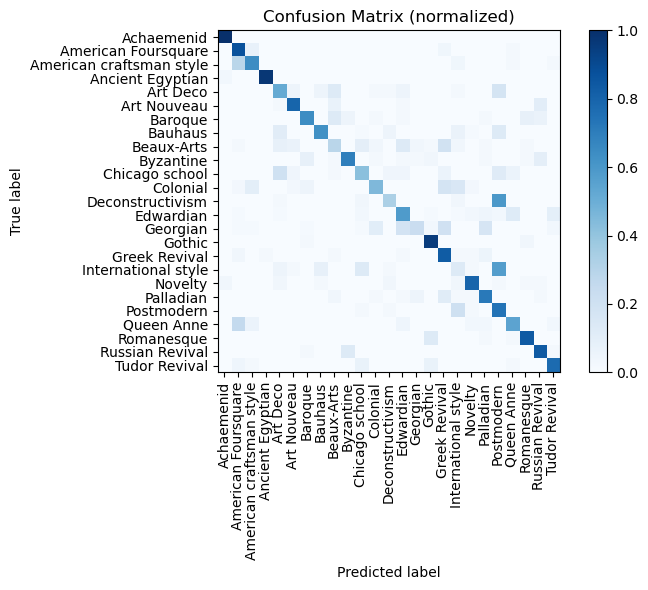

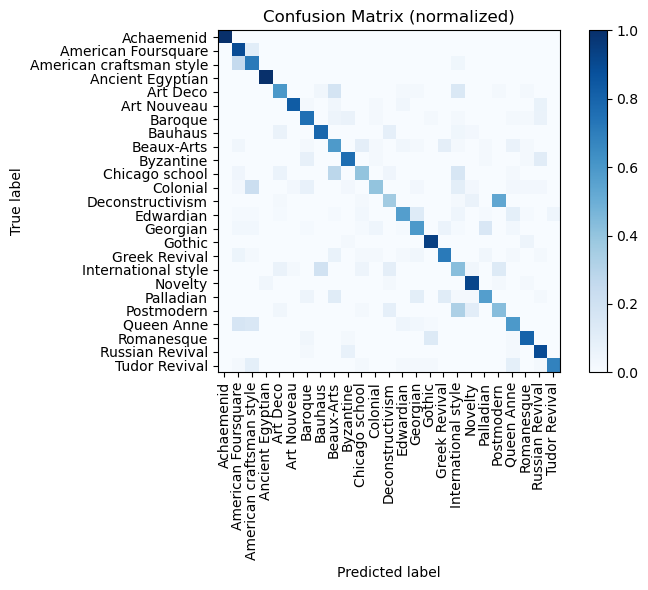

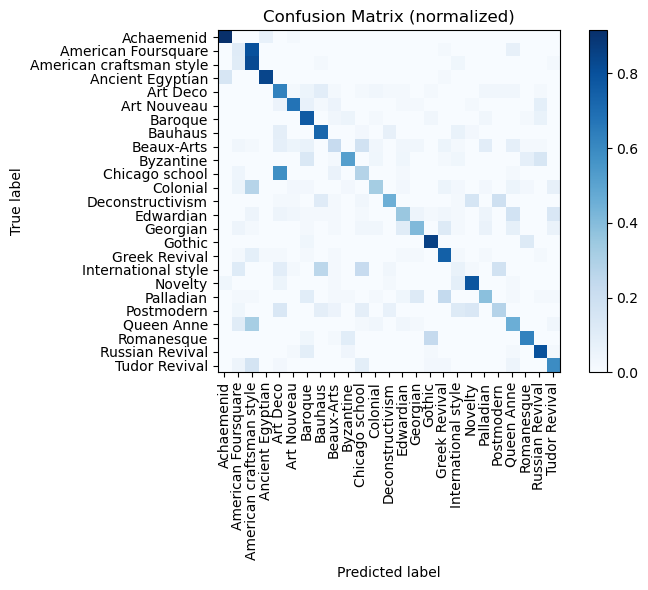

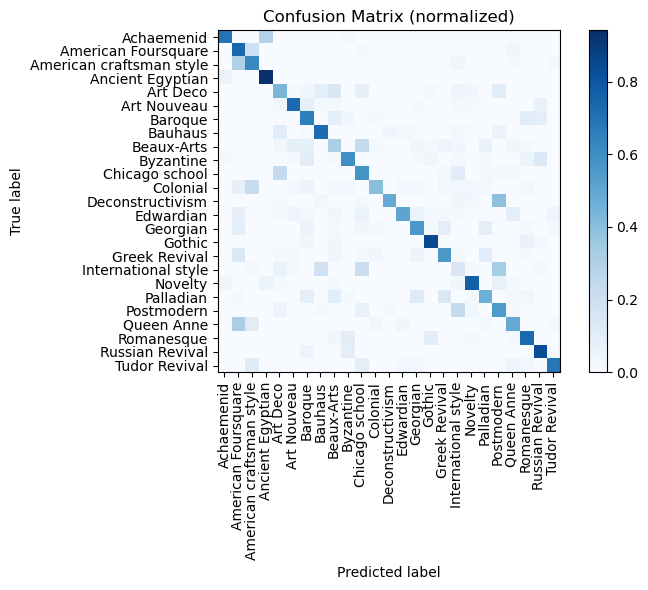

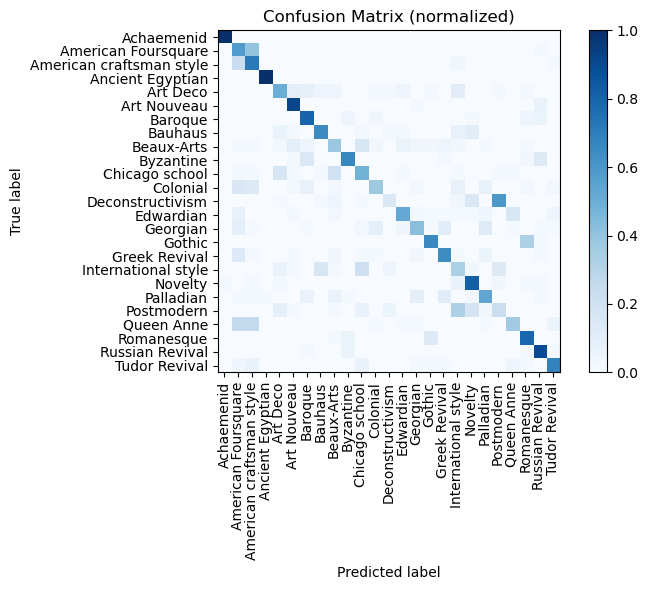

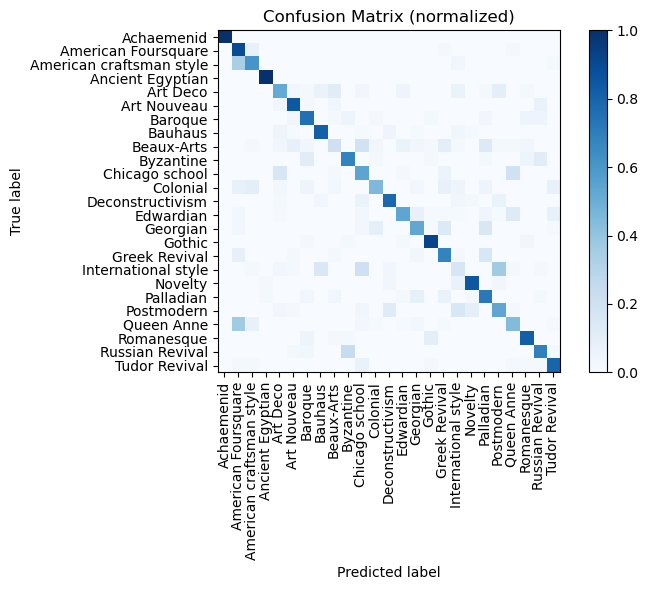

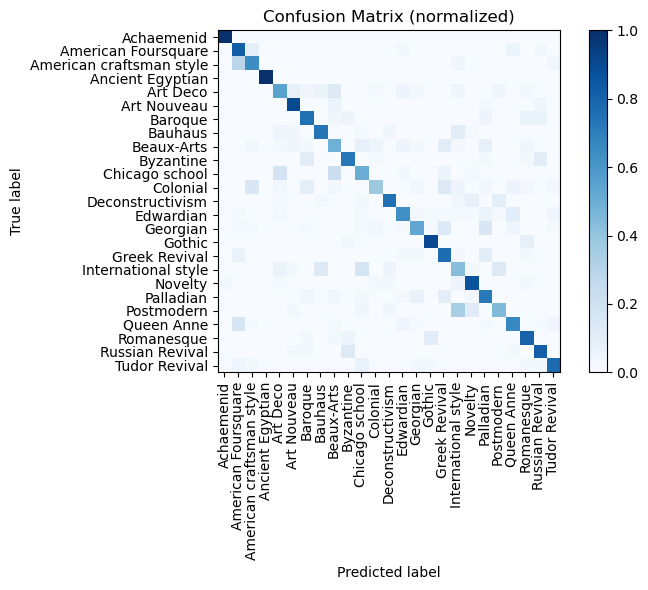

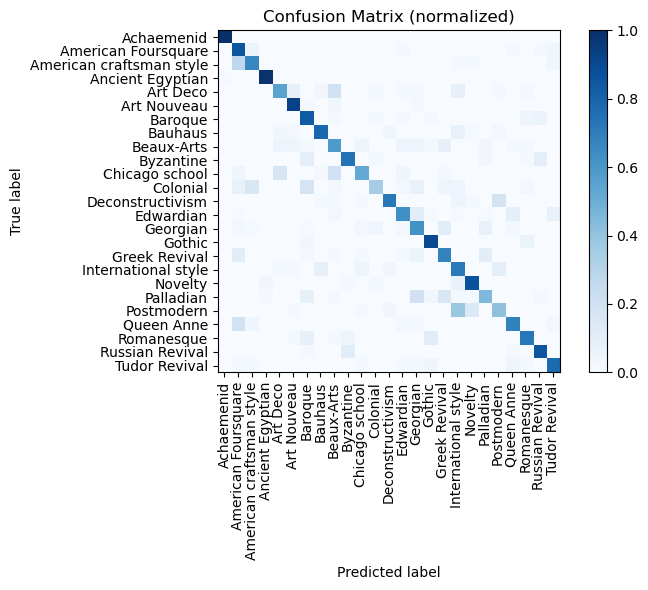

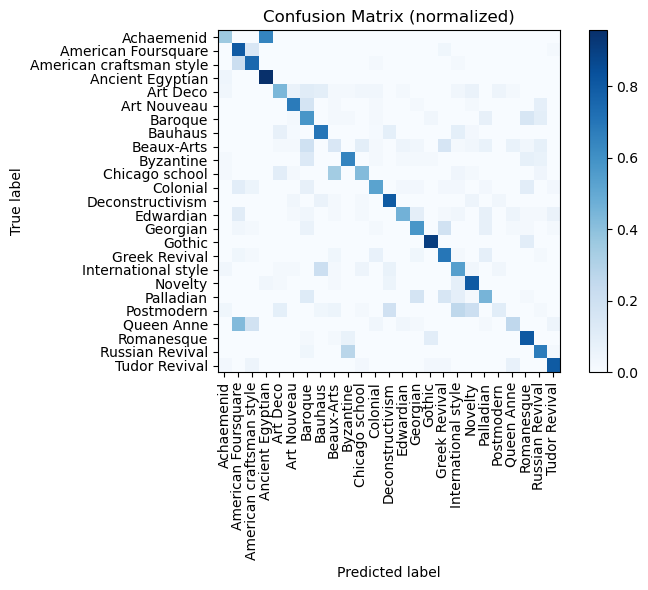

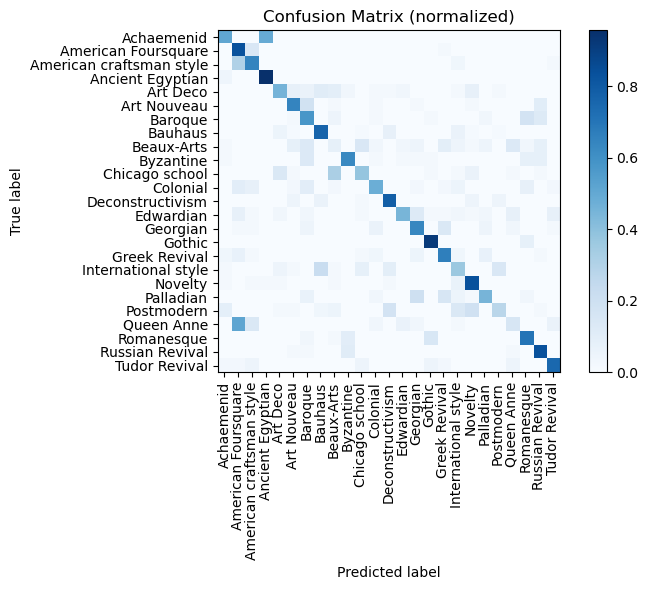

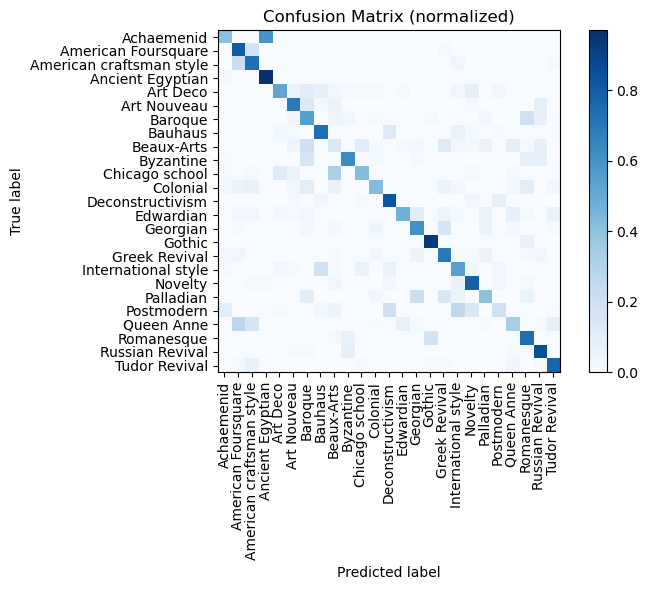

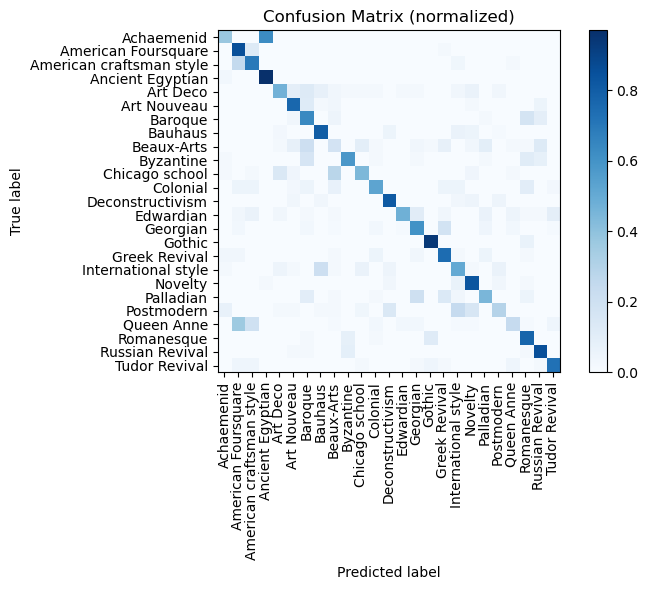

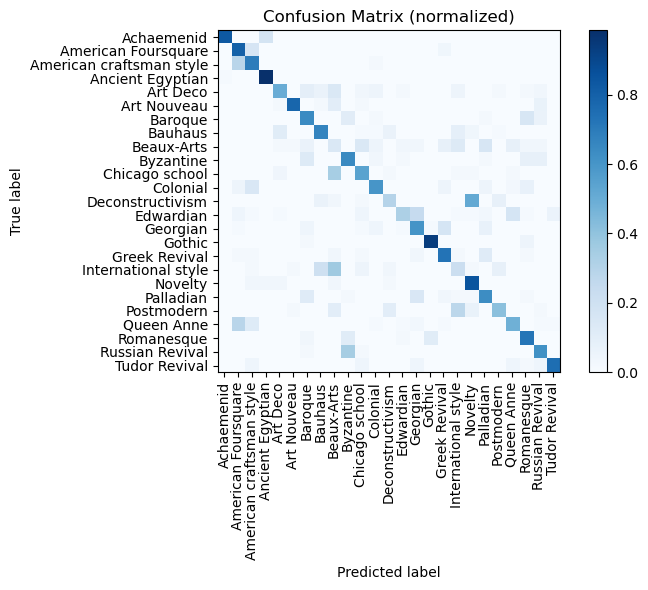

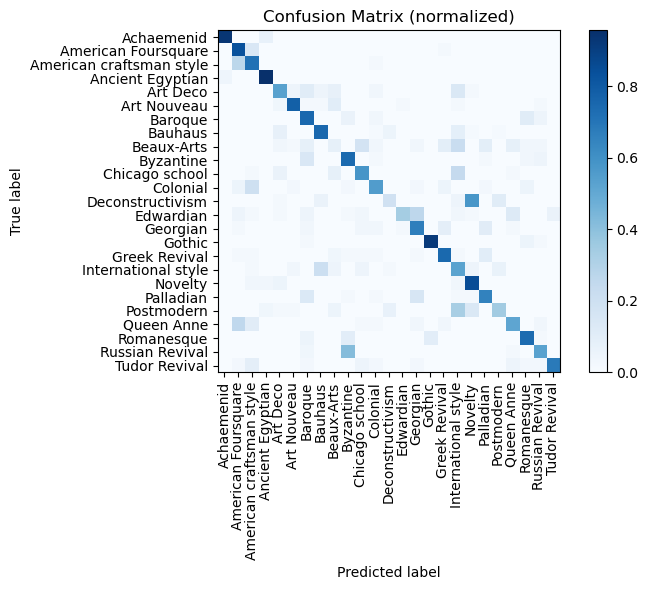

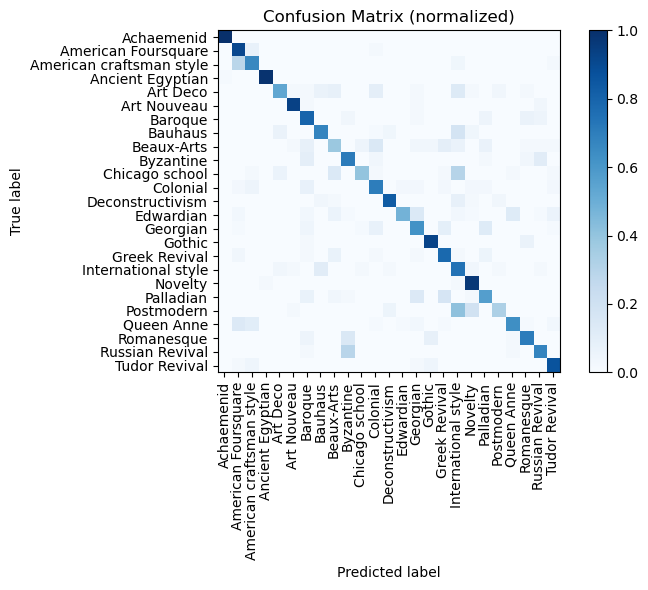

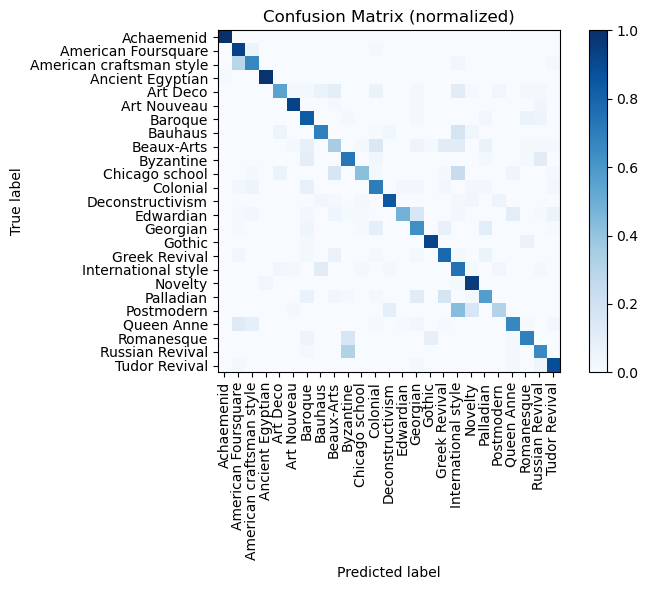

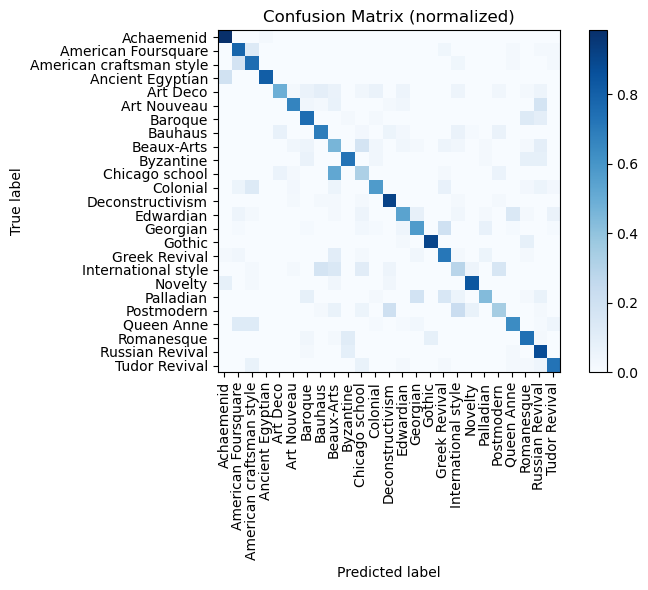

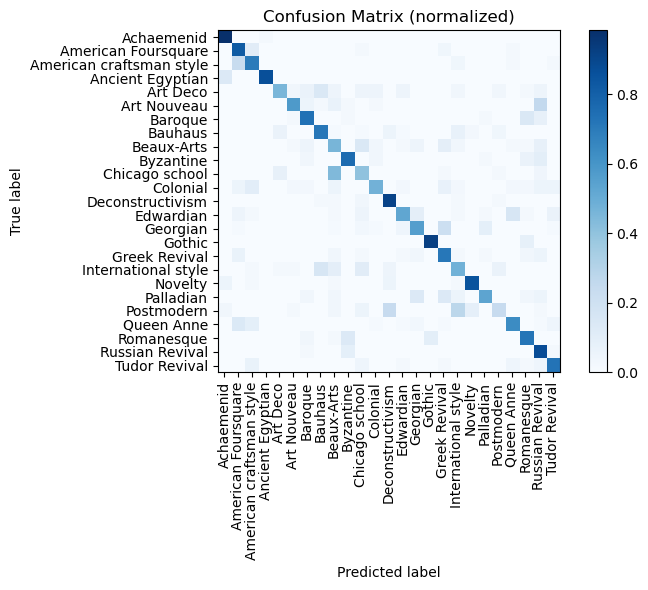

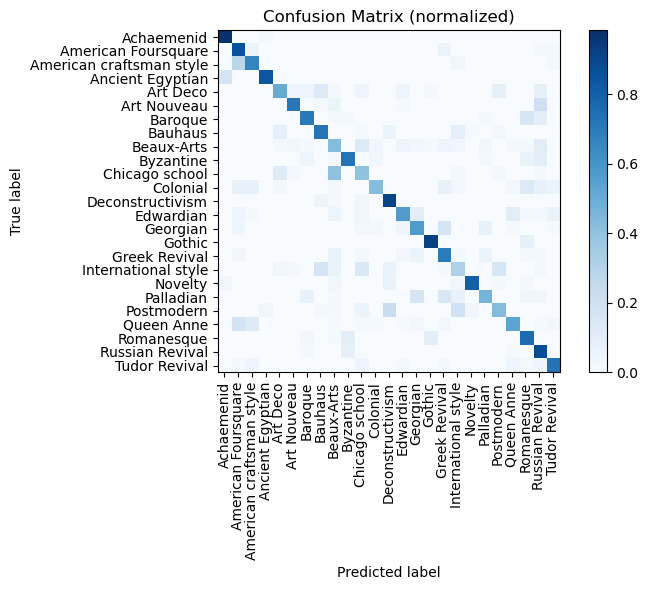

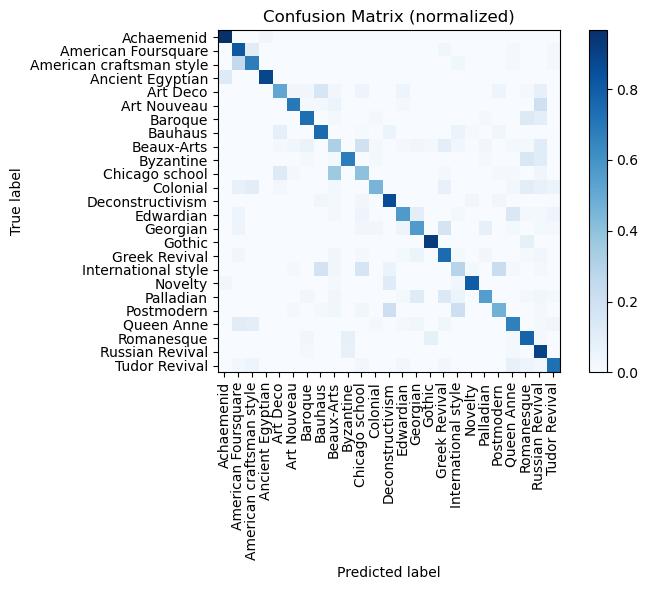

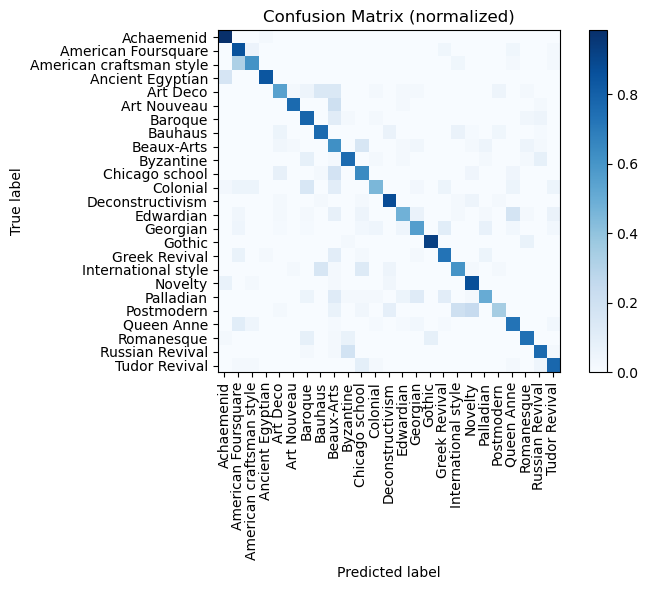

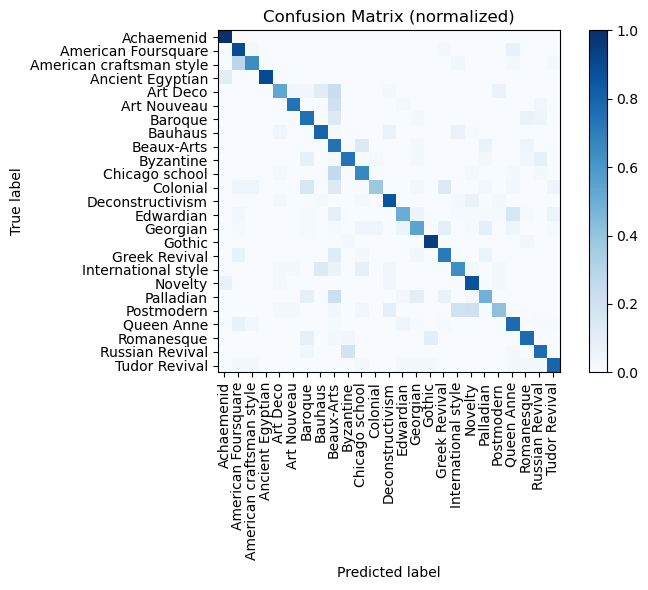

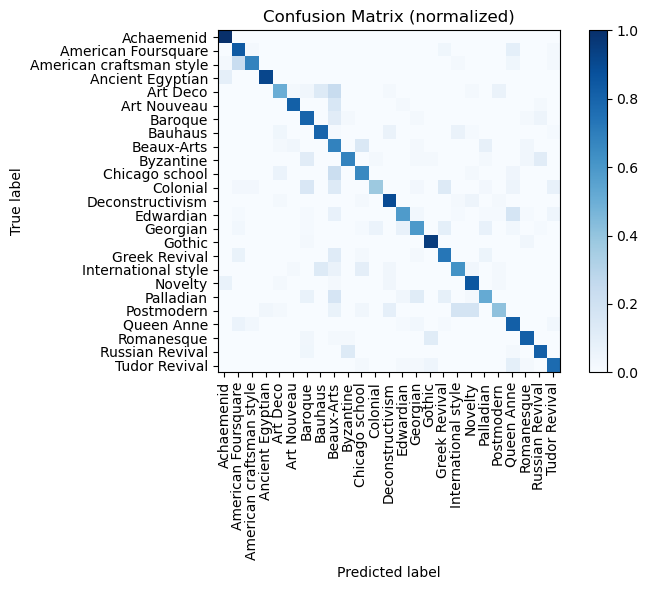

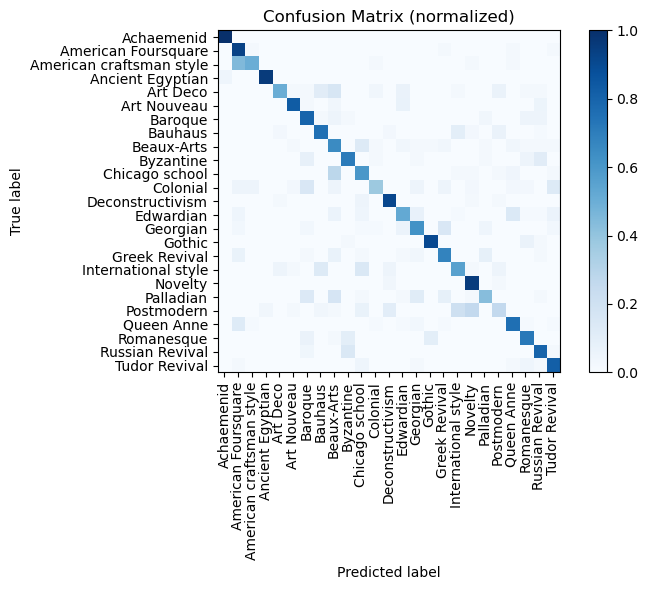

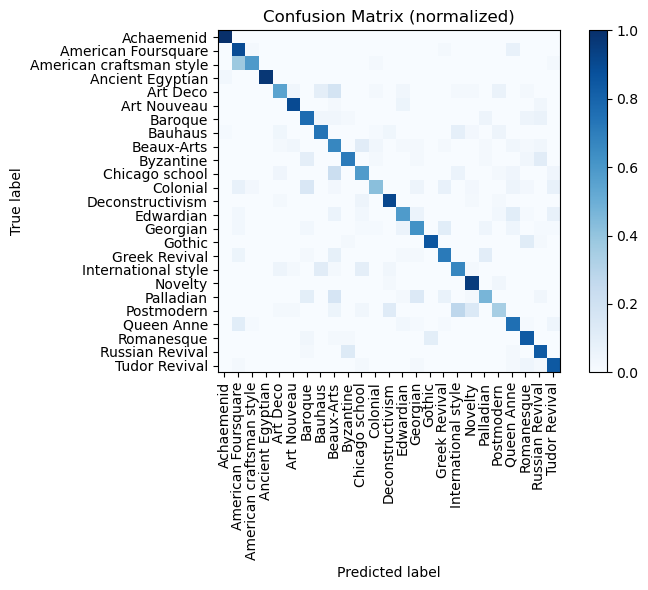

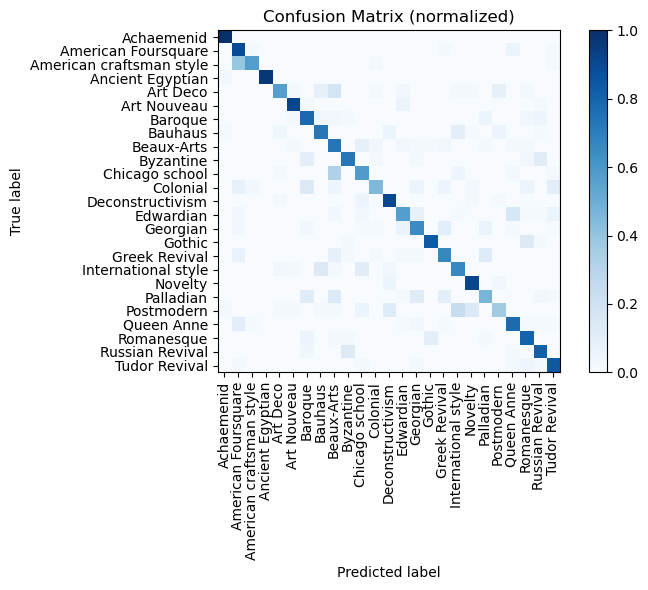

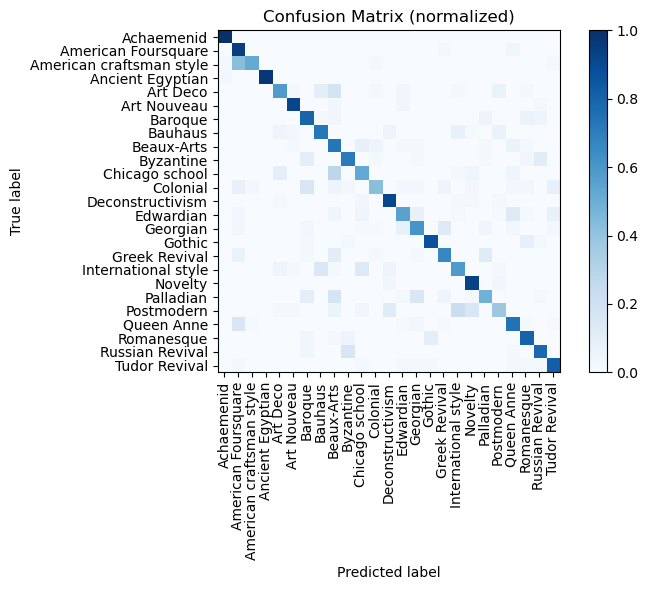

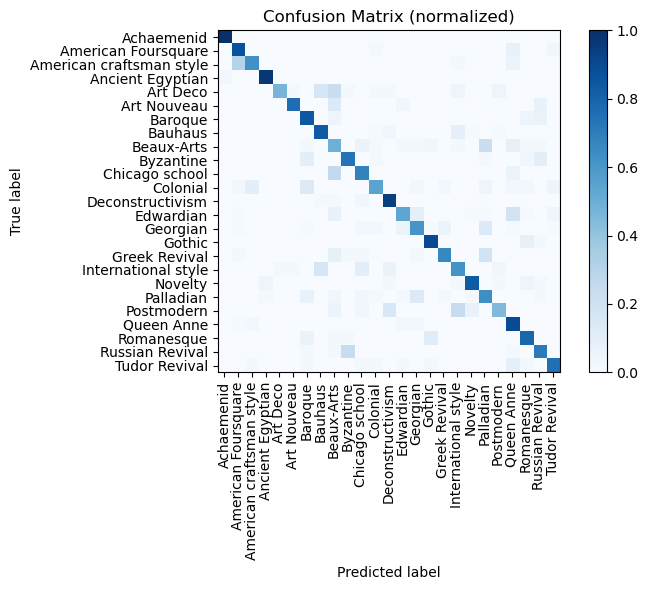

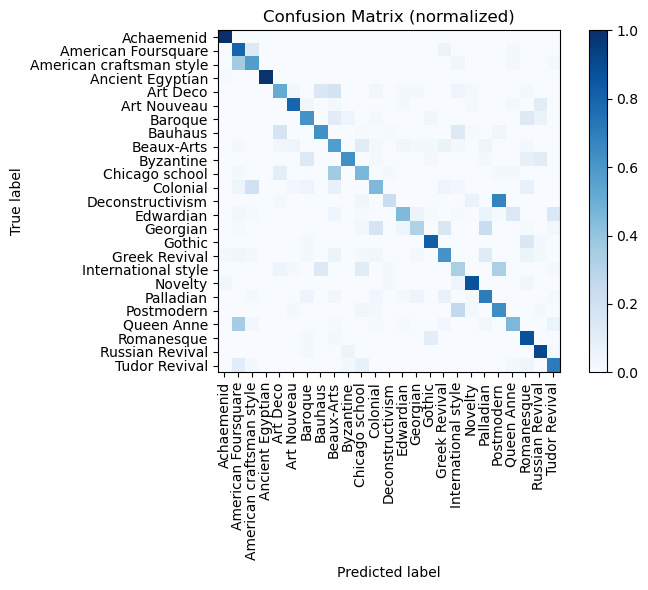

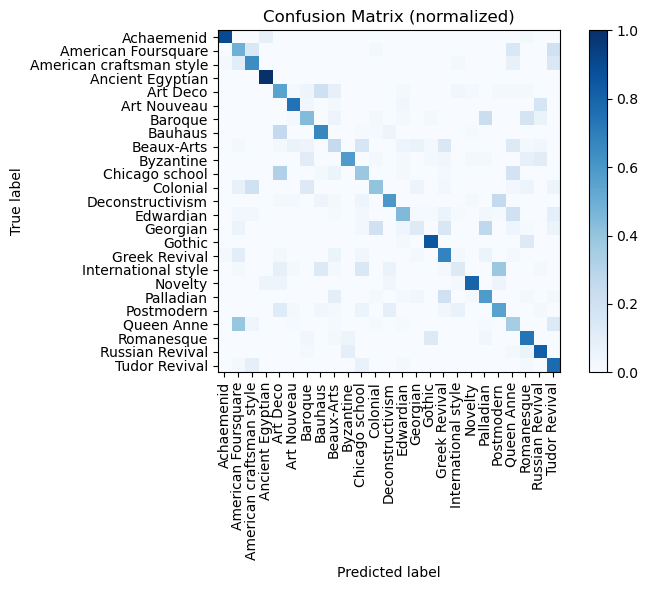

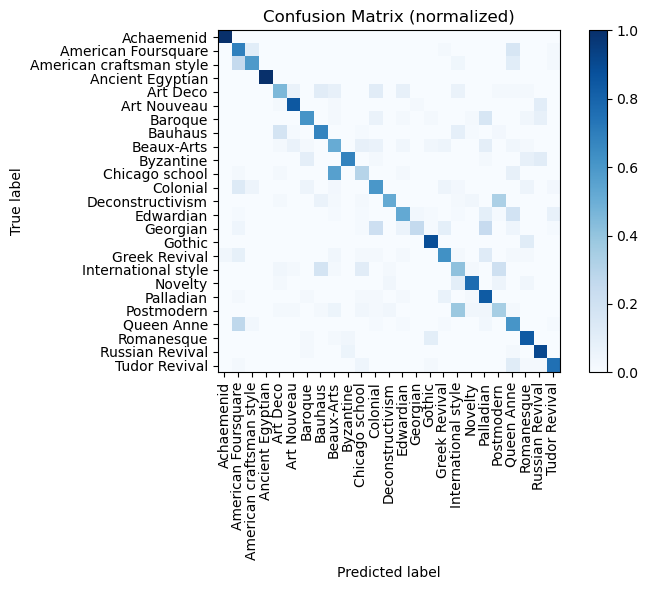

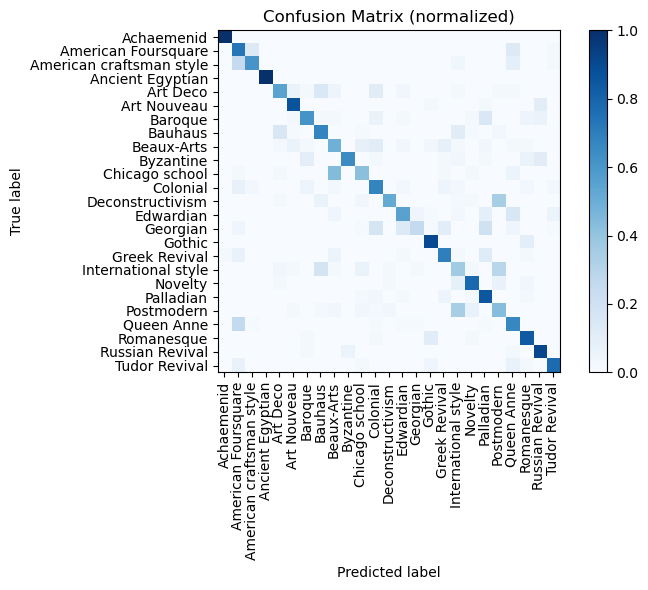

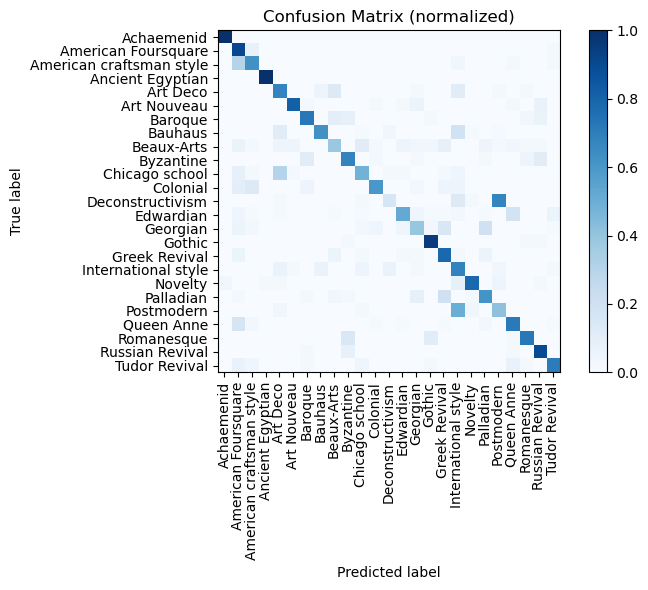

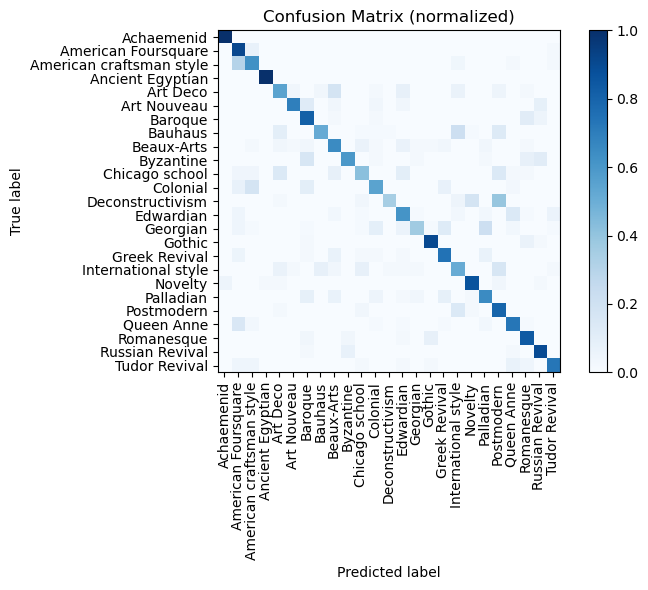

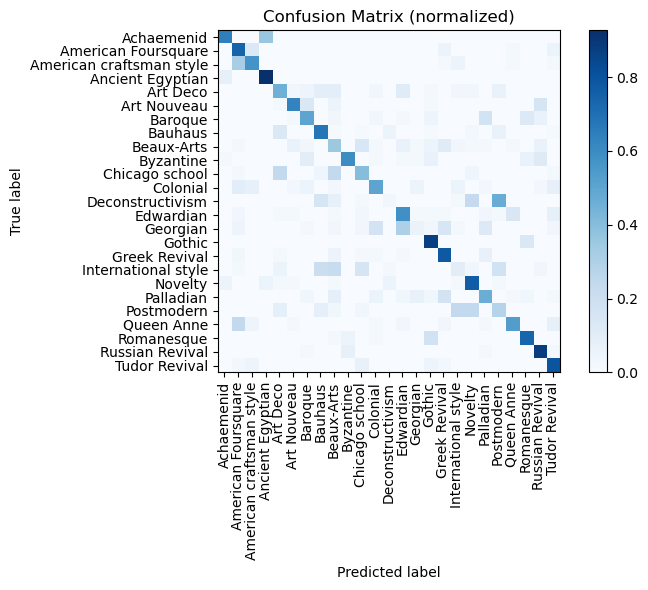

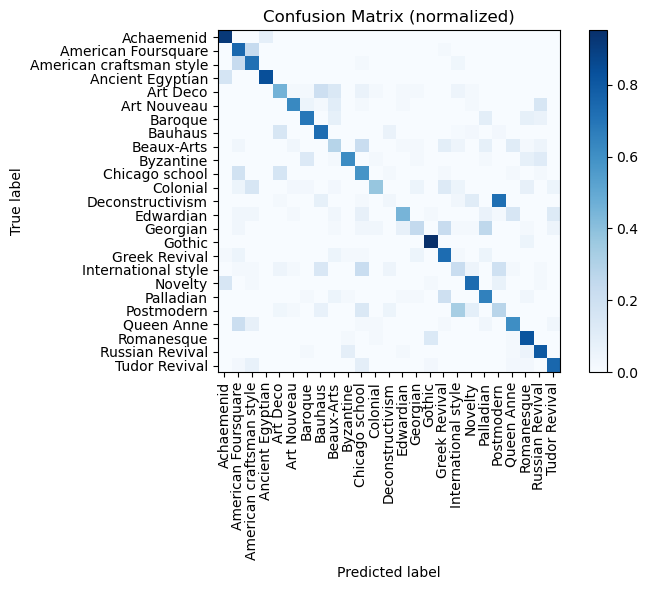

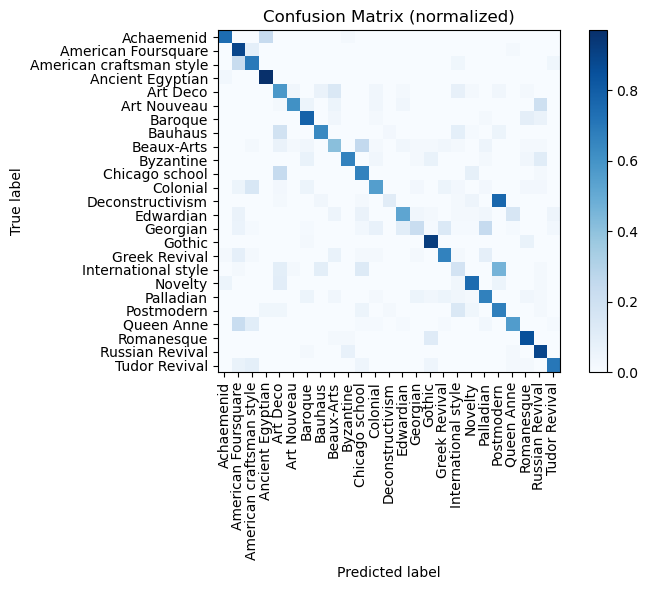

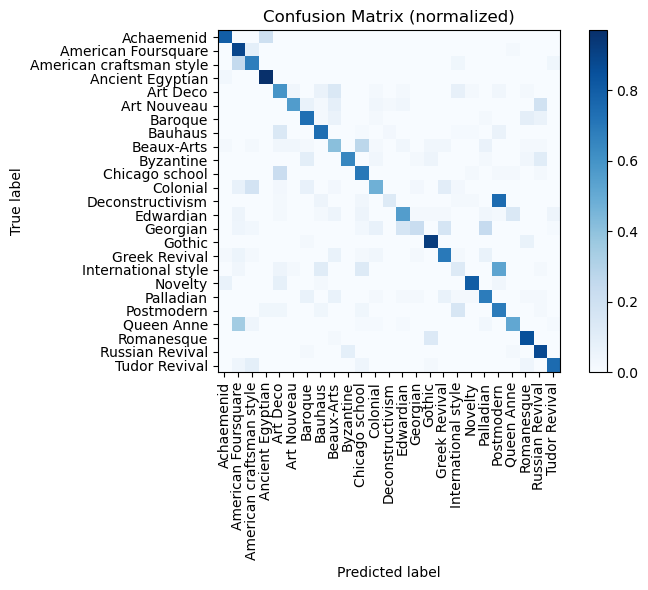

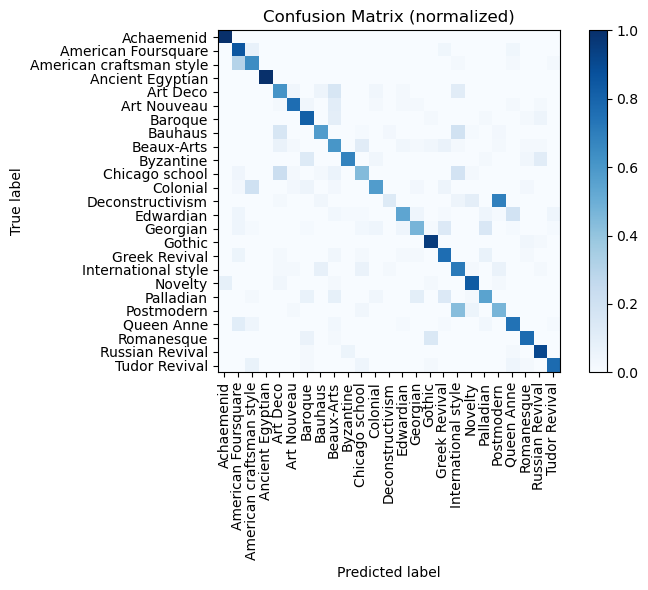

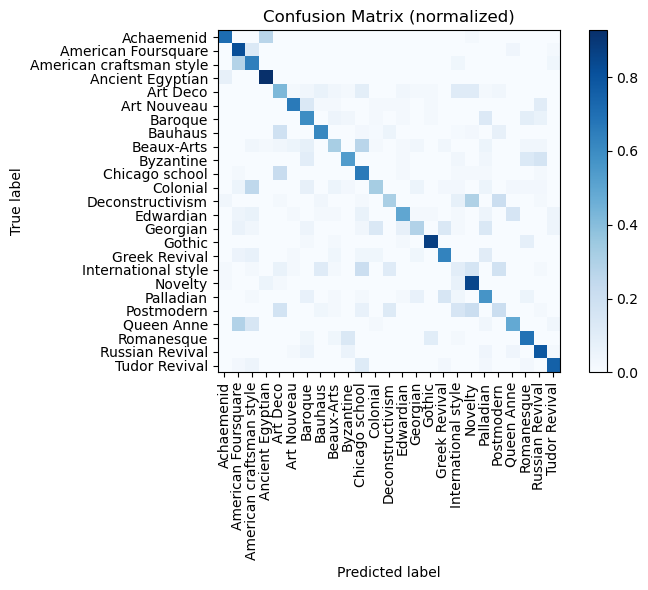

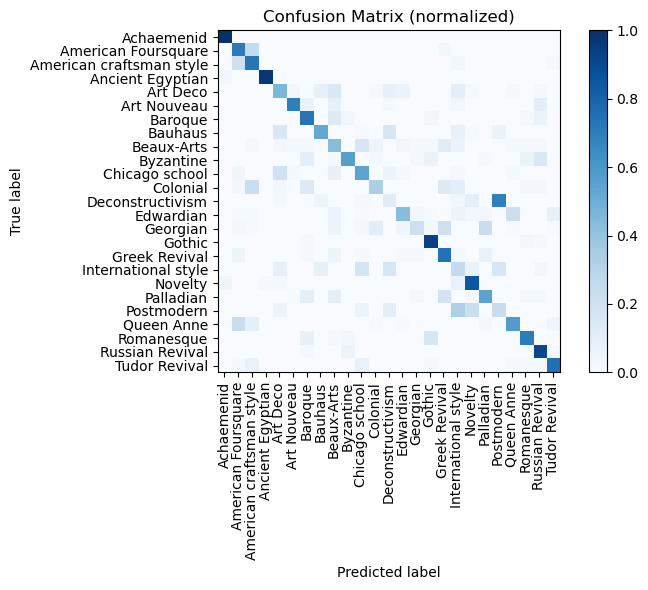

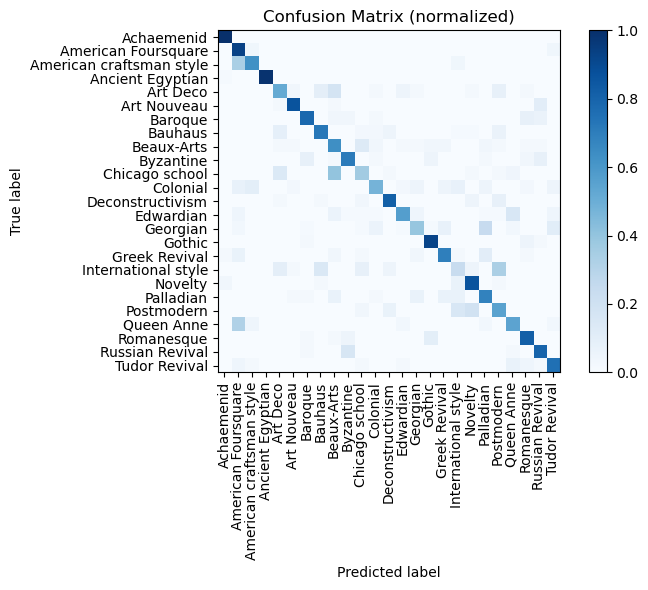

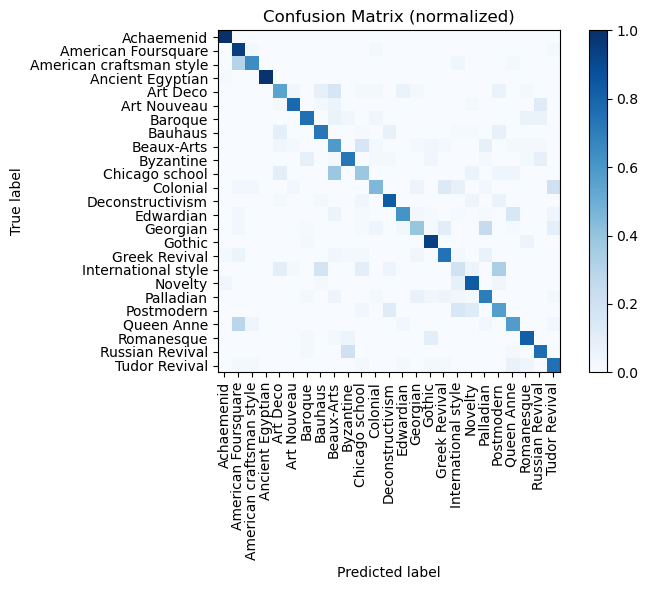

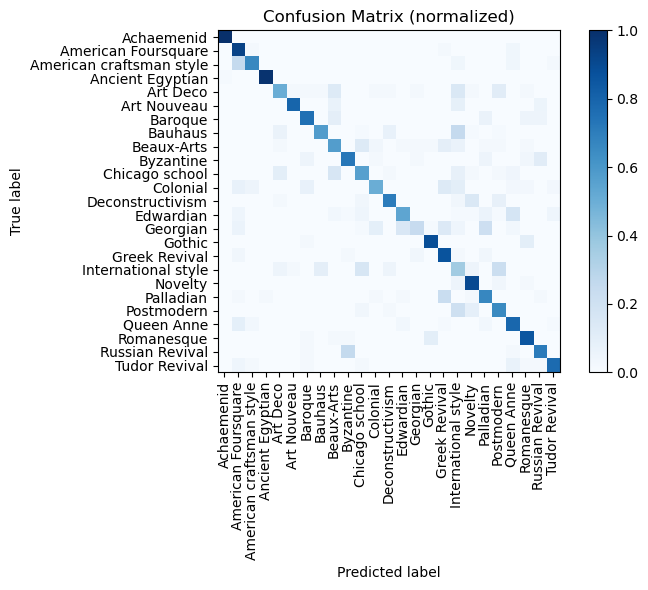

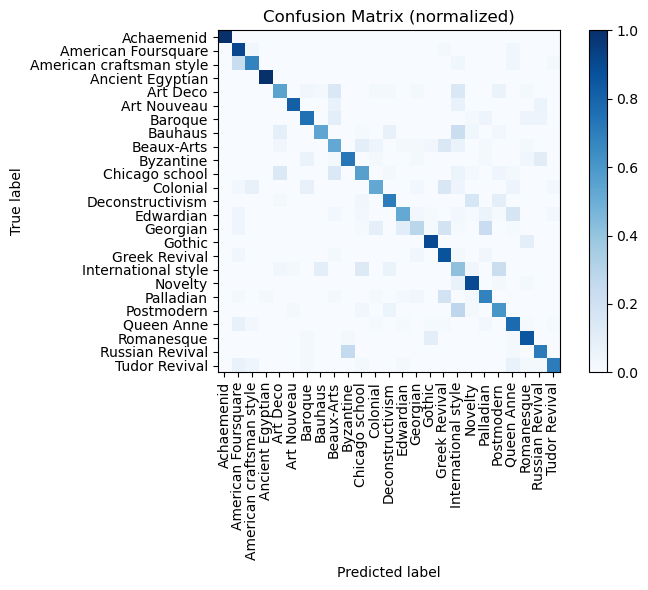

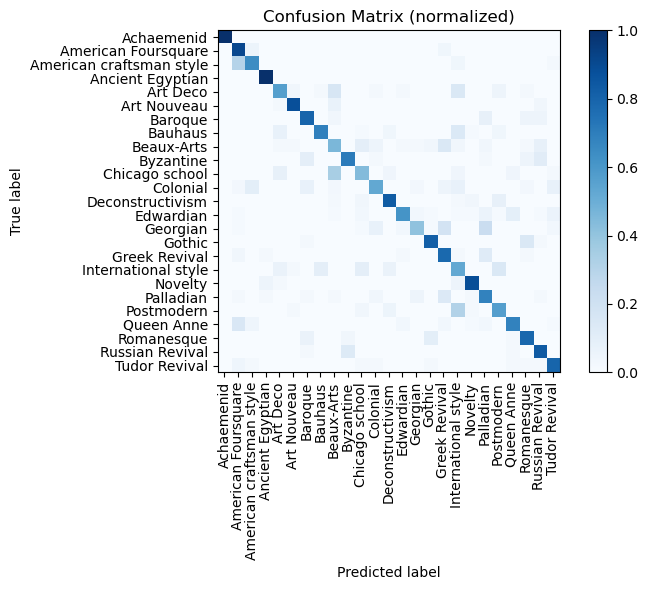

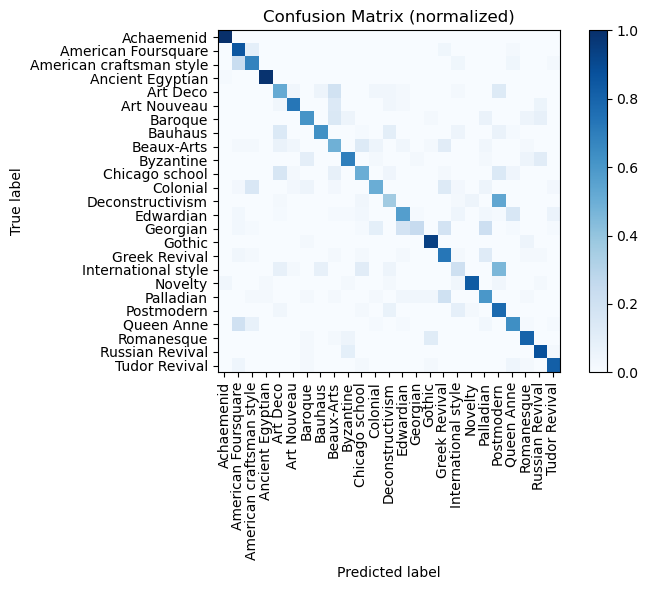

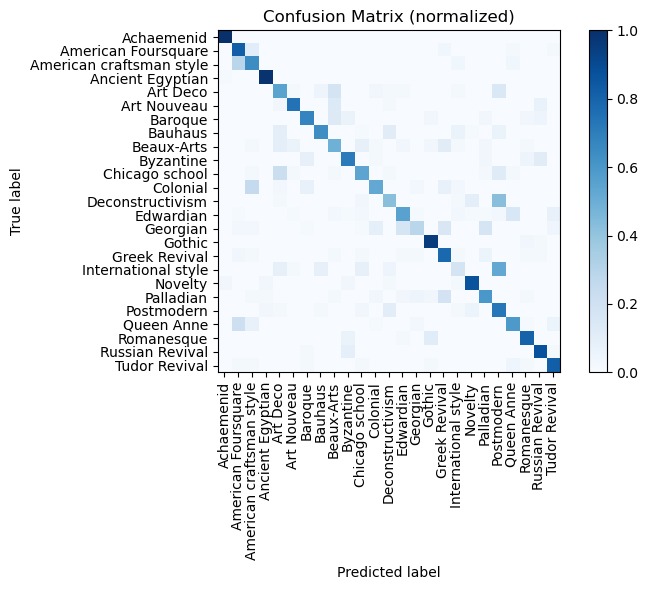

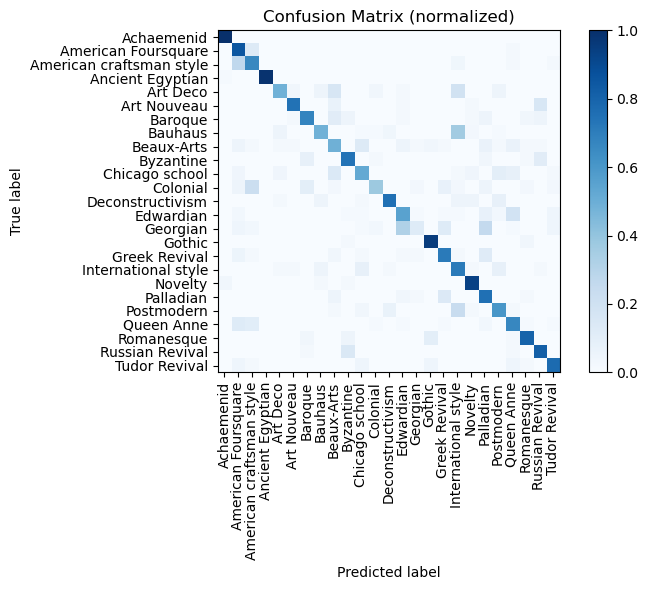

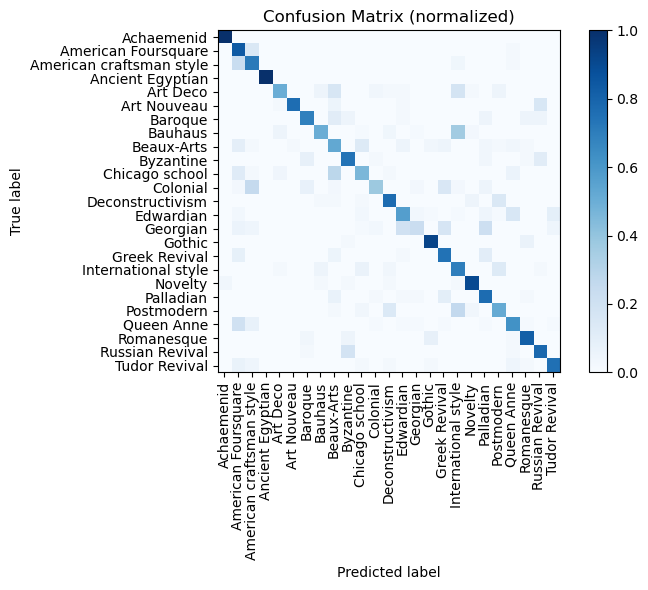

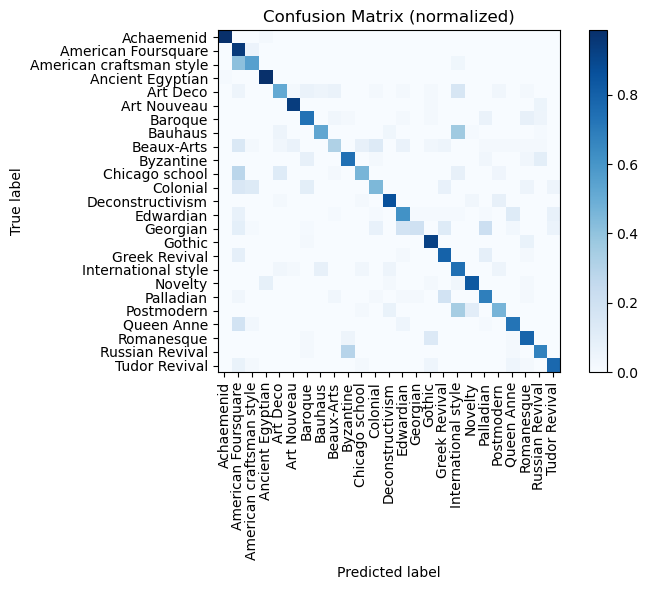

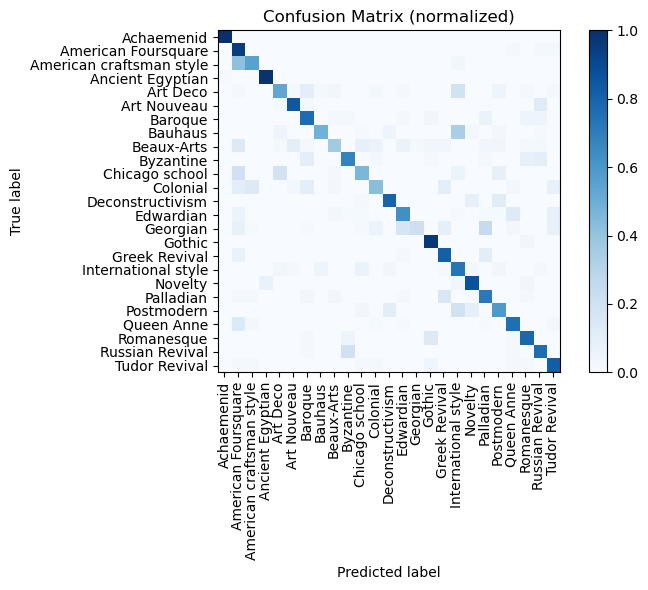

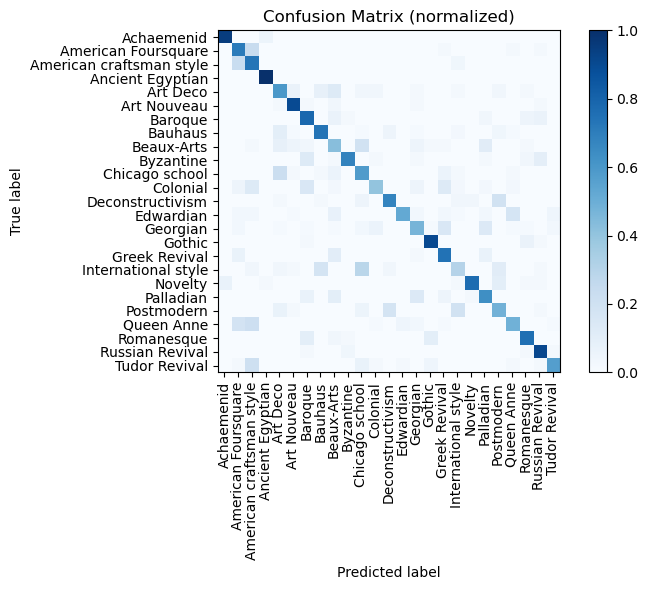

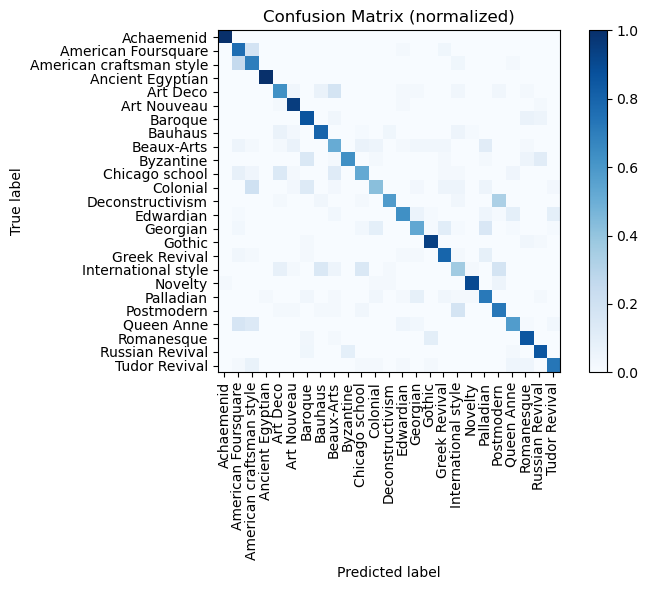

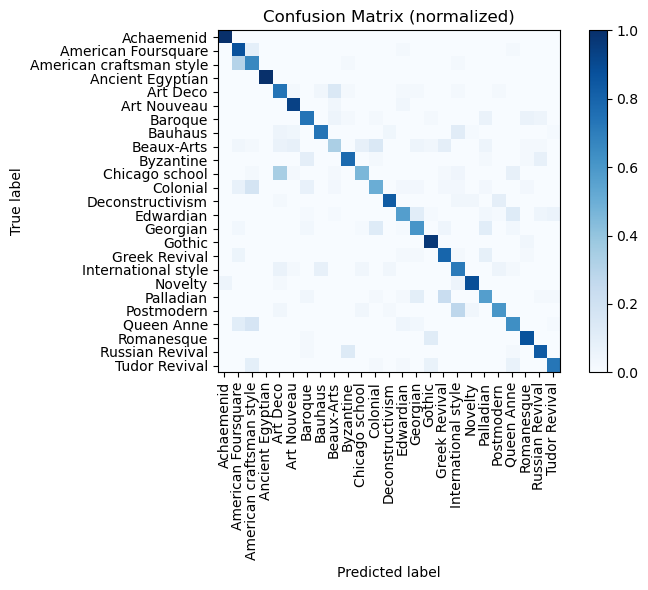

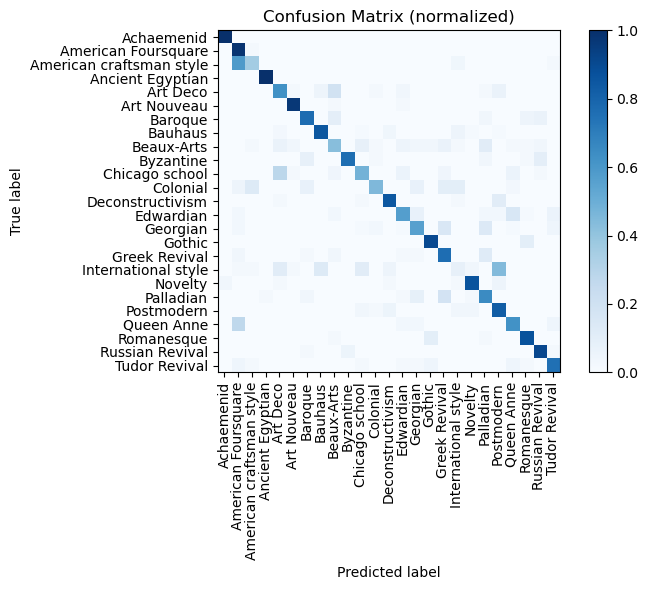

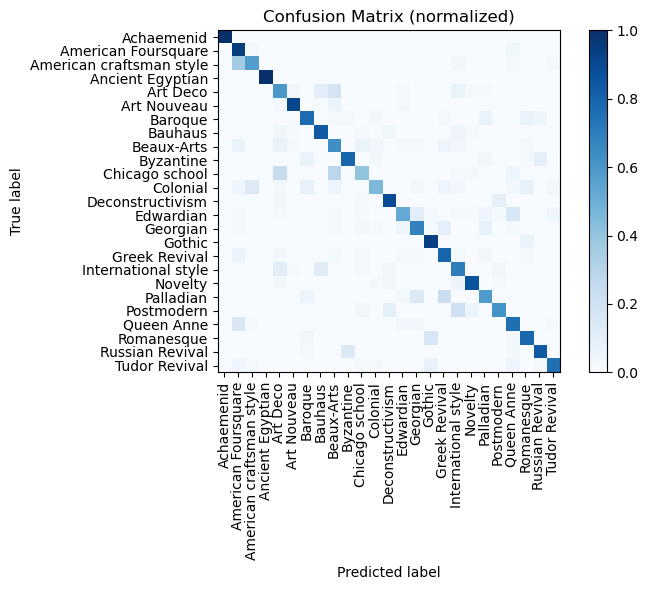

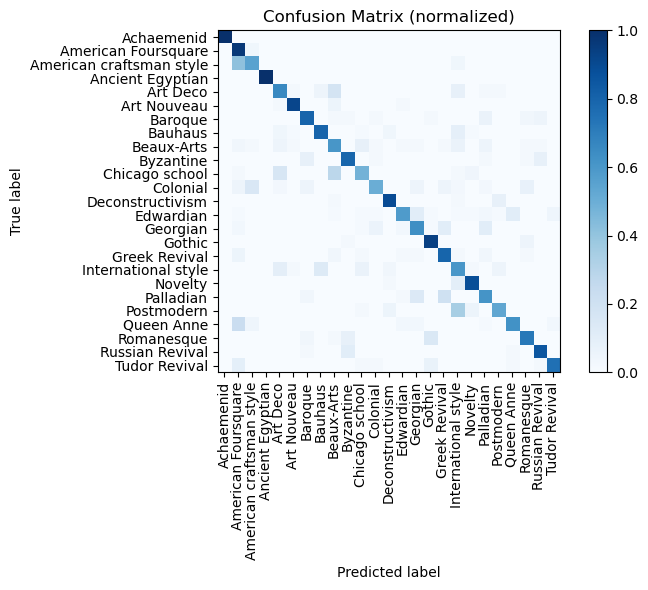

In [10]:
# make the warning containing "quick_gelu" an exception
# because some openai models need the "force_quick_gelu=True" set
warnings.filterwarnings("error",".*quick_gelu.*",UserWarning)
counter=1
for model_name, pretrained_name in MODELS_LIST:
    print(f"Model {model_name}, {pretrained_name}  ({counter}/{len(MODELS_LIST)})")
    try:
    
        model, _, preprocess = open_clip.create_model_and_transforms(
            model_name=model_name,
            pretrained=pretrained_name
        )
    
    except UserWarning:
        model, _, preprocess = open_clip.create_model_and_transforms(
            model_name=model_name,
            pretrained=pretrained_name,
            force_quick_gelu=True
        )

    tokenizer = open_clip.get_tokenizer(model_name)
    model.to(device).eval()
    ds.transform=preprocess # type: ignore
    dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=8, pin_memory=True)

    top1, macro_f1, top2, top3, y_true, y_pred, probs=evaluate(model,tokenizer,dl)

    # To measure latency correctly the batch size should be set to 1 (so new DataLoader needed)
    dl = DataLoader(ds, batch_size=1, shuffle=False, num_workers=0, pin_memory=True)
    latency_ms = measure_latency(model,dl,num_batches=min(250, len(ds)),warmup_batches=50)
    
    row = {
        "Timestamp": datetime.now(ZoneInfo("Europe/Rome")).isoformat(),
        "Model": model_name,
        "Pretrained": pretrained_name,
        "Scenario": f"Zero-shot ({SPLIT})",
        "Techniques": f"Prompt ensemble({len(TEMPLATES)} prompts)",
        "Top-1 Acc": round(float(top1), 4),
        "Top-2 Acc": round(float(top2), 4),
        "Top-3 Acc": round(float(top3), 4),
        "Macro-F1": round(float(macro_f1), 4),
        "Latency (ms/img)": f"{latency_ms['mean_ms']:.2f} ± {latency_ms['std_ms']:.2f} ms",
        "Classes": int(len(classnames)),
        "Batch size": int(BATCH_SIZE)
    }
    save_to_csv(row)
    save_performance_per_class(y_true,y_pred,model_name)
    del model
    del tokenizer
    del dl
    torch.cuda.empty_cache()
    gc.collect()
    counter+=1
    